In [1]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
daring = pd.read_csv("/home/kyomukama/ACE/Patient outcomes/HLOS/ML_developement/Data/ml_data_encoded.csv")

In [3]:
camonet = pd.read_csv("/home/kyomukama/ACE/Patient outcomes/HLOS/ML_developement/Data/test_data.csv")

In [4]:
data = pd.concat([daring, camonet], axis=0)

# Correlation 

Correaltion with the target variable and also how the different variable correlate with each other

Index(['Resistance', 'growth1', 'cormobid_condition', 'age', 'name_of_rrh',
       'ward', 'num_infection_sites', 'sex', 'antibiotics_prescribed',
       'referral'],
      dtype='object')


/tmp/ipykernel_84010/1964570330.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_corr.values, y=top_corr.index, palette='RdBu')


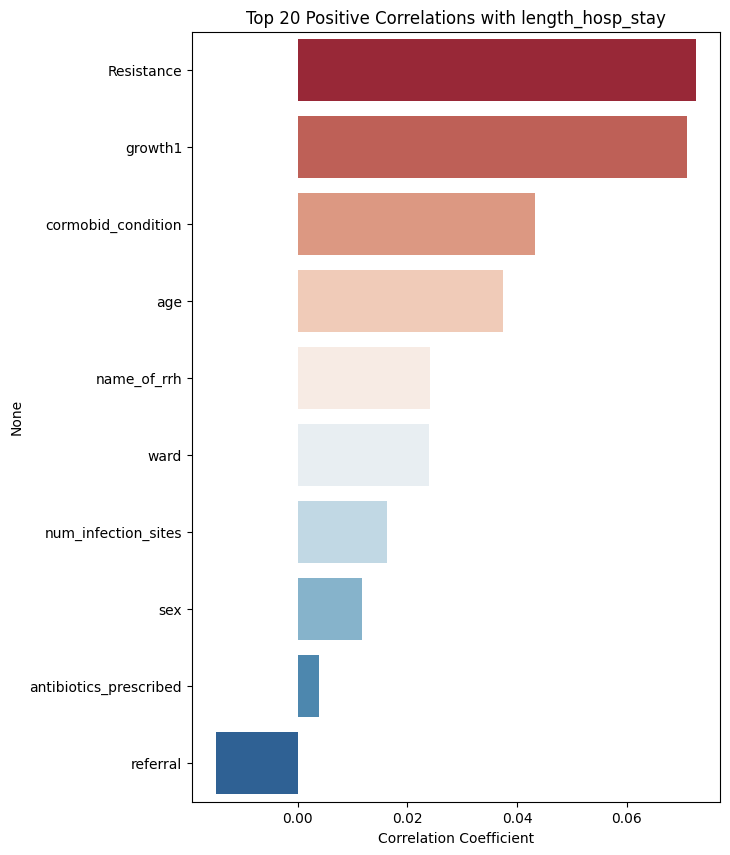

In [5]:
def plot_correlations(df, target_column, n_top = 39):
    
    # Calculate correlations with target variable
    correlations = df.corr()[target_column].sort_values(ascending=False)
    
    # Get top N most correlated features (excluding the target itself)
    top_corr = correlations[1:n_top+1]

    print(top_corr.index)
    
    # Create figure with two subplots
    plt.figure(figsize=(15, 10))
    
    # Plot 1: Horizontal bar chart of top correlations
    plt.subplot(1, 2, 1)
    sns.barplot(x=top_corr.values, y=top_corr.index, palette='RdBu')
    plt.title(f'Top {n_top} Positive Correlations with {target_column}')
    plt.xlabel('Correlation Coefficient')

plot_correlations(data, 'length_hosp_stay', n_top=20)


<Figure size 1500x1000 with 0 Axes>

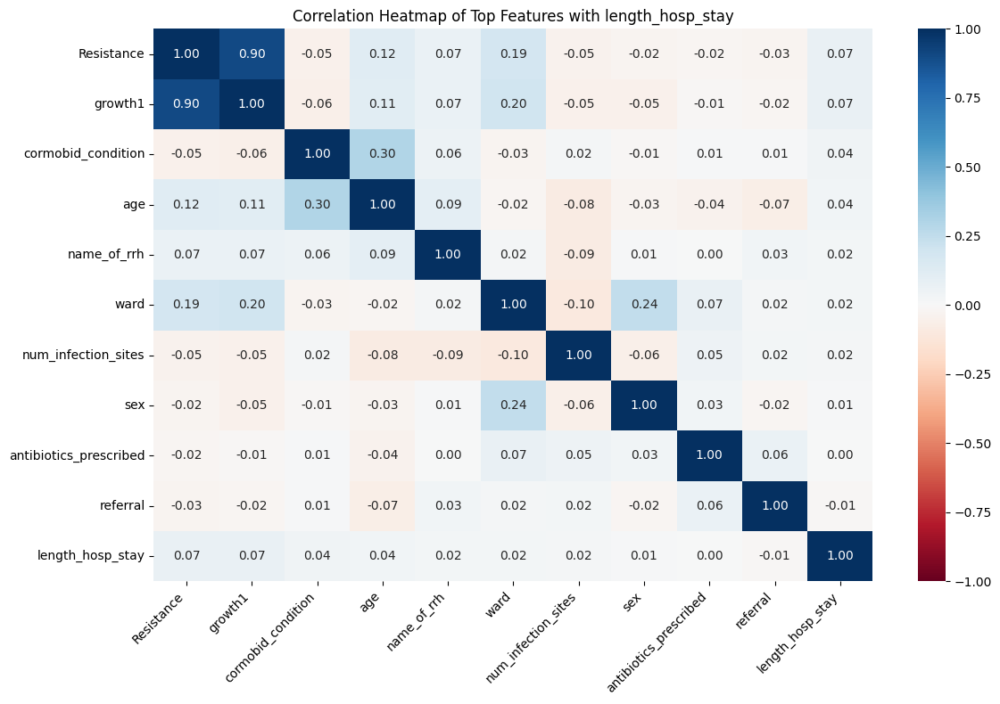

In [6]:
def plot_correlations(df, target_column, n_top=20):
    
    # Calculate correlations with target variable
    correlations = df.corr()[target_column].sort_values(ascending=False)
    
    # Get top N most correlated features (excluding the target itself)
    top_corr = correlations[1:n_top+1]
    #bottom_corr = correlations[-(n_top):]
    
    # Create figure with two subplots
    plt.figure(figsize=(15, 10))
    
    # Create heatmap of top correlated features
    plt.figure(figsize=(12, 8))
    top_features = list(top_corr.index[:10]) + [target_column]  # Top 10 + target
    correlation_matrix = df[top_features].corr()
    
    sns.heatmap(correlation_matrix, 
                annot=True,
                cmap='RdBu',
                vmin=-1, 
                vmax=1,
                center=0,
                fmt='.2f')
    plt.title(f'Correlation Heatmap of Top Features with {target_column}')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

plot_correlations(data, 'length_hosp_stay', n_top=20)

# ML

## Data

In [8]:
print(data.shape)

data.head()

(2360, 11)


,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
0,36.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,13.0
1,57.0,3.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,6.0,46.0
2,8.0,2.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0
3,1.0,3.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,7.0,4.0
4,21.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,3.0


In [10]:
data.isna().sum()

age                       1
num_infection_sites       1
sex                       1
referral                  1
cormobid_condition        1
antibiotics_prescribed    1
growth1                   1
Resistance                1
name_of_rrh               1
ward                      1
length_hosp_stay          1
dtype: int64

In [11]:
data.dropna(inplace=True)

In [12]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# the independent variables set
X = data.drop(columns = ['length_hosp_stay'])

# VIF dataframe
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns

# calculating VIF for each feature
vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]

print(vif_data)


                  feature        VIF
0                     age   2.806506
1     num_infection_sites   3.721116
2                     sex   2.057488
3                referral   1.269072
4      cormobid_condition   1.529108
5  antibiotics_prescribed   4.117006
6                 growth1  10.708724
7              Resistance   9.736106
8             name_of_rrh   3.086506
9                    ward   4.757805


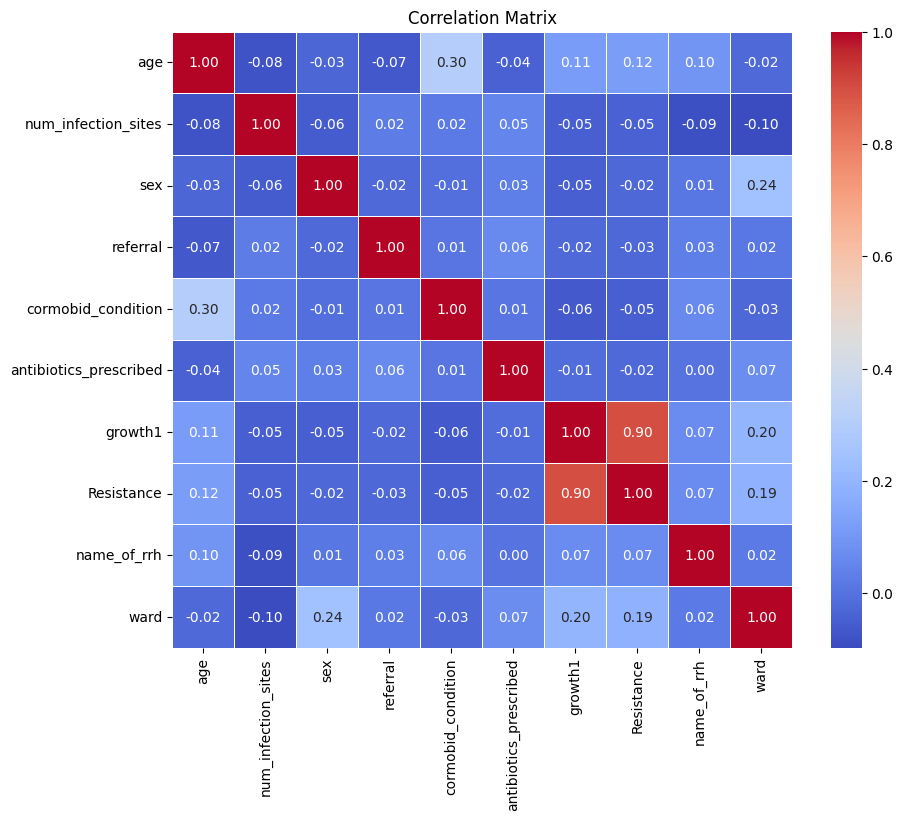

In [13]:
def draw_correlation_matrix(data):

    try:
        # Calculate the correlation matrix
        correlation_matrix = data.corr()

        # Create the heatmap
        plt.figure(figsize=(10, 8))  # Adjust the figure size as needed
        sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
        plt.title("Correlation Matrix")
        plt.show()

    except ValueError:
        print("Error: DataFrame contains non-numeric data. Correlation matrix can only be calculated for numeric data.")
    except Exception as e:
        print(f"An unexpected error occurred: {e}")

draw_correlation_matrix(data.drop(columns='length_hosp_stay')) 

In [15]:
data.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
0,36.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,13.0
1,57.0,3.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,6.0,46.0
2,8.0,2.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0
3,1.0,3.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,7.0,4.0
4,21.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,3.0


In [16]:
data.isna().sum()

age                       0
num_infection_sites       0
sex                       0
referral                  0
cormobid_condition        0
antibiotics_prescribed    0
growth1                   0
Resistance                0
name_of_rrh               0
ward                      0
length_hosp_stay          0
dtype: int64

##  Bootstrap method

In [17]:
data = data.dropna()

In [18]:
data.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward,length_hosp_stay
0,36.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,13.0
1,57.0,3.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,6.0,46.0
2,8.0,2.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0
3,1.0,3.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,7.0,4.0
4,21.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,3.0


In [20]:
# Set random seed for reproducibility
SEED = 1 
np.random.seed(SEED)

# Define target percentiles to identify rare cases
low_threshold = np.percentile(data["length_hosp_stay"], 25)  # Lower quartile
high_threshold = np.percentile(data["length_hosp_stay"], 75)  # Upper quartile

# Identify minority samples (e.g., extreme low & high values)
minority_samples = data[(data["length_hosp_stay"] <= low_threshold) | (data["length_hosp_stay"] >= high_threshold)]

# Bootstrap resampling (with replacement) to balance the dataset
bootstrapped_minority = minority_samples.sample(n=len(data), replace=True, random_state=SEED)

# Combine with the original dataset
balanced_data = pd.concat([data, bootstrapped_minority])

# Shuffle the final dataset
balanced_data = balanced_data.sample(frac=1, random_state=SEED).reset_index(drop=True)

# Display the new balanced dataset
print(balanced_data.shape)


(4716, 11)


In [21]:
from sklearn.model_selection import train_test_split

X1_train, X_test, y1_train, y_test = train_test_split(data.drop(columns = 'length_hosp_stay'), data['length_hosp_stay'], test_size = 0.5, random_state = 42)

In [22]:
X_train, X_val, y_train, y_val = train_test_split(balanced_data.drop(columns = 'length_hosp_stay'), balanced_data['length_hosp_stay'], test_size = 0.2, random_state = 42)

In [23]:
X_train.shape, X_val.shape

((3772, 10), (944, 10))

In [24]:
X_train.columns

Index(['age', 'num_infection_sites', 'sex', 'referral', 'cormobid_condition',
       'antibiotics_prescribed', 'growth1', 'Resistance', 'name_of_rrh',
       'ward'],
      dtype='object')

Shapiro-Wilk Test: Statistic=0.9724975228309631, p-value=3.405838286852139e-29
Log-transformed sample does not look Gaussian (reject H0)


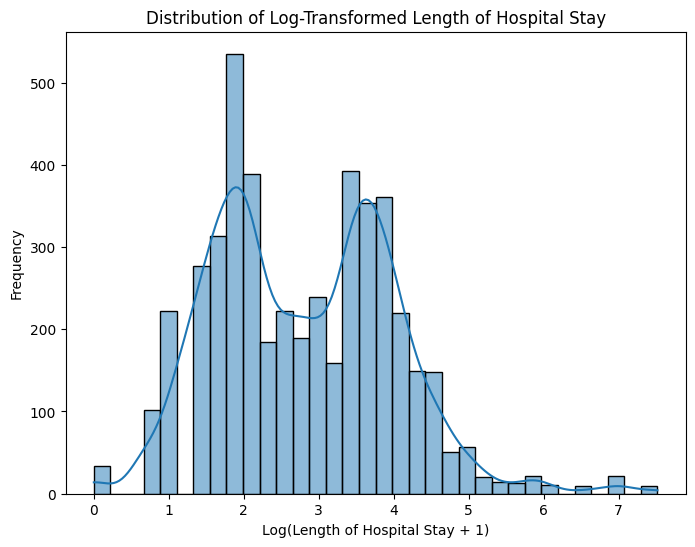

In [25]:
from scipy import stats

# Assuming you have a DataFrame named 'data' with a 'length_hosp_stay' column

# Log transform the 'length_hosp_stay' column
log_length_hosp_stay = np.log1p(balanced_data['length_hosp_stay'])
# Visualize the log-transformed data
plt.figure(figsize=(8, 6))
sns.histplot(log_length_hosp_stay, kde=True)
plt.title('Distribution of Log-Transformed Length of Hospital Stay')
plt.xlabel('Log(Length of Hospital Stay + 1)')
plt.ylabel('Frequency')

# Save the plot
plt.savefig("log_length_hosp_stay_distribution.png")

# Perform a normality test (e.g., Shapiro-Wilk)
shapiro_test = stats.shapiro(log_length_hosp_stay)
print(f"Shapiro-Wilk Test: Statistic={shapiro_test.statistic}, p-value={shapiro_test.pvalue}")

# Interpretation (example)
alpha = 0.05  # Significance level
if shapiro_test.pvalue > alpha:
    print("Log-transformed sample looks Gaussian (fail to reject H0)")
else:
    print("Log-transformed sample does not look Gaussian (reject H0)")

# Show the plot
plt.show()


Shapiro-Wilk Test: Statistic=0.9827320575714111, p-value=2.54364020530246e-16
Log-transformed sample does not look Gaussian (reject H0)


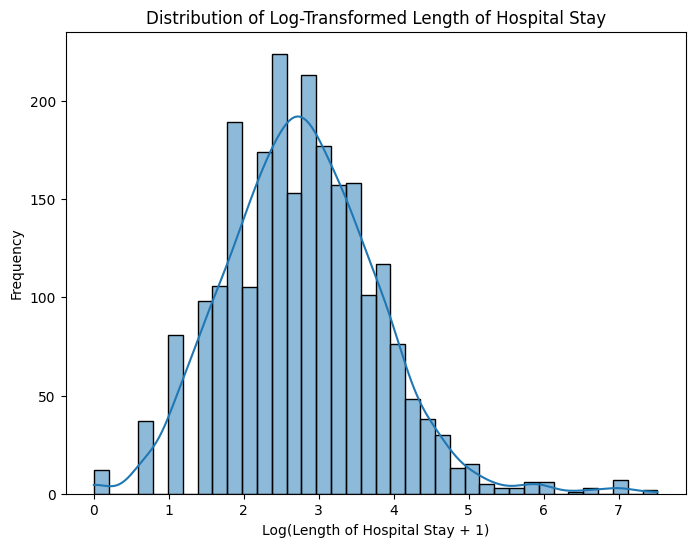

In [26]:
from scipy import stats

# Assuming you have a DataFrame named 'data' with a 'length_hosp_stay' column

# Log transform the 'length_hosp_stay' column
log_length_hosp_stay = np.log1p(data['length_hosp_stay'])

# Visualize the log-transformed data
plt.figure(figsize=(8, 6))
sns.histplot(log_length_hosp_stay, kde=True)
plt.title('Distribution of Log-Transformed Length of Hospital Stay')
plt.xlabel('Log(Length of Hospital Stay + 1)')
plt.ylabel('Frequency')

# Save the plot
plt.savefig("log_length_hosp_stay_distribution.png")

# Perform a normality test (e.g., Shapiro-Wilk)
shapiro_test = stats.shapiro(log_length_hosp_stay)
print(f"Shapiro-Wilk Test: Statistic={shapiro_test.statistic}, p-value={shapiro_test.pvalue}")

# Interpretation (example)
alpha = 0.05  # Significance level
if shapiro_test.pvalue > alpha:
    print("Log-transformed sample looks Gaussian (fail to reject H0)")
else:
    print("Log-transformed sample does not look Gaussian (reject H0)")

# Show the plot
plt.show()


In [27]:
X_train.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward
3135,74.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,4.0,9.0
4320,33.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,2.0,4.0
599,26.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,3.0,4.0
2121,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0
3410,43.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,3.0,9.0


In [28]:
X_test.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward
342,75.0,2.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,9.0
1137,47.0,2.0,1.0,0.0,1.0,0.0,0.0,0.0,4.0,4.0
678,25.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,3.0,1.0
361,37.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,4.0
1602,18.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,7.0,9.0


In [29]:
X_val.head()

,age,num_infection_sites,sex,referral,cormobid_condition,antibiotics_prescribed,growth1,Resistance,name_of_rrh,ward
1210,10.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,9.0
2029,22.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,8.0,9.0
3192,18.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,8.0,4.0
3725,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,7.0,2.0
2256,16.0,2.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,4.0


Shapiro-Wilk Test: Statistic=0.9810792207717896, p-value=2.786216049543988e-11
Log-transformed sample does not look Gaussian (reject H0)


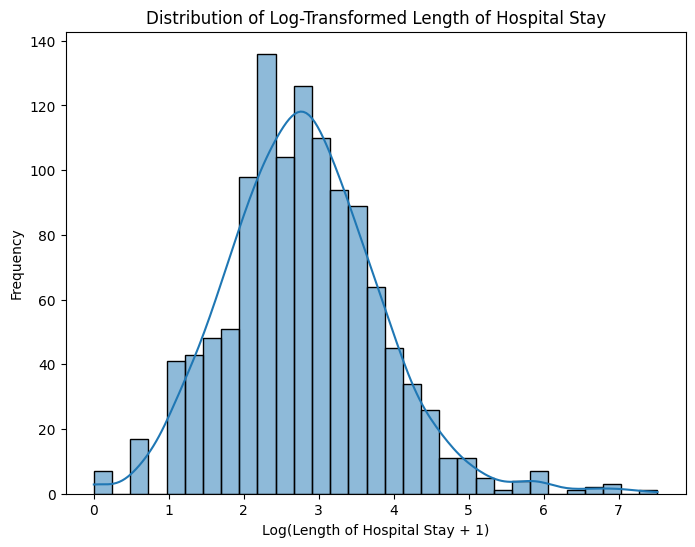

In [30]:
from scipy import stats

# Assuming you have a DataFrame named 'data' with a 'length_hosp_stay' column

# Log transform the 'length_hosp_stay' column
log_length_hosp_stay = np.log1p(y_test)

# Visualize the log-transformed data
plt.figure(figsize=(8, 6))
sns.histplot(log_length_hosp_stay, kde=True)
plt.title('Distribution of Log-Transformed Length of Hospital Stay')
plt.xlabel('Log(Length of Hospital Stay + 1)')
plt.ylabel('Frequency')

# Save the plot
plt.savefig("log_length_hosp_stay_distribution.png")

# Perform a normality test (e.g., Shapiro-Wilk)
shapiro_test = stats.shapiro(log_length_hosp_stay)
print(f"Shapiro-Wilk Test: Statistic={shapiro_test.statistic}, p-value={shapiro_test.pvalue}")

# Interpretation (example)
alpha = 0.05  # Significance level
if shapiro_test.pvalue > alpha:
    print("Log-transformed sample looks Gaussian (fail to reject H0)")
else:
    print("Log-transformed sample does not look Gaussian (reject H0)")

# Show the plot
plt.show()


## Modelling

# Huber model

Validation Metrics (after anti-log transformation):
Mean Absolute Error: 30.56
Root Mean Squared Error: 107.16
R-squared Score: -0.0320

Test Metrics (after anti-log transformation):
Mean Absolute Error: 24.27
Root Mean Squared Error: 93.89
R-squared Score: -0.0210


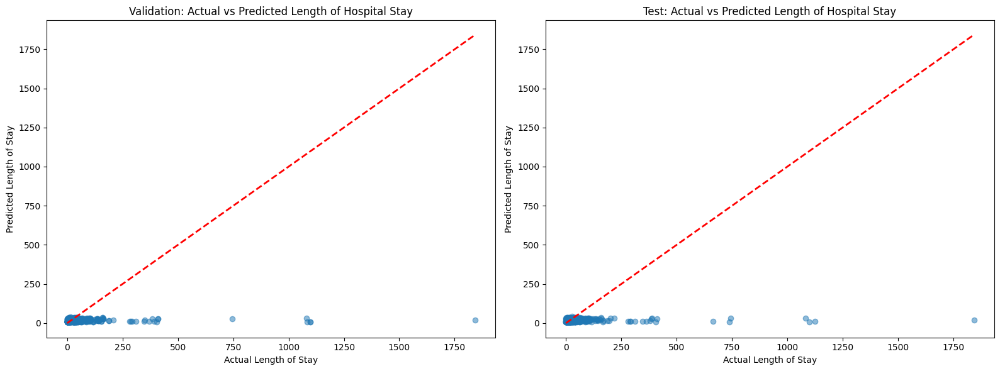

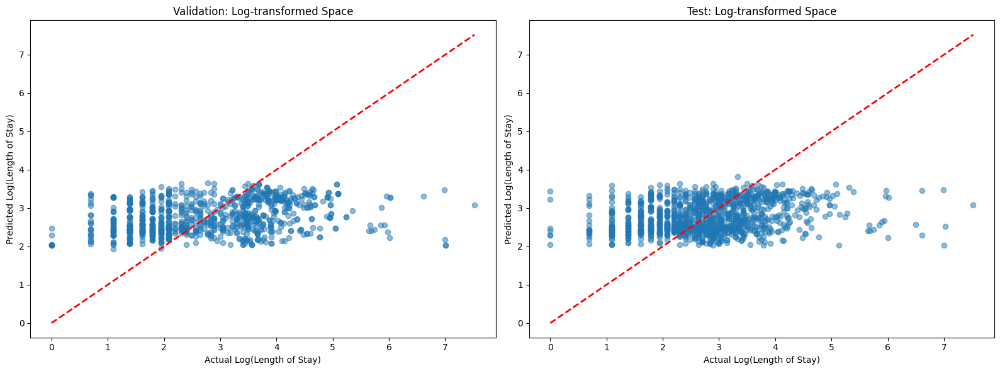


Log-space Validation Metrics:
Mean Absolute Error: 0.9393
Root Mean Squared Error: 1.1588
R-squared Score: 0.0970

Log-space Test Metrics:
Mean Absolute Error: 0.7680
Root Mean Squared Error: 1.0034
R-squared Score: 0.0461


In [31]:
import numpy as np
import pandas as pd
from sklearn.linear_model import HuberRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Apply log transformation to target variables
y_train_log = np.log1p(y_train)  # log1p = log(1+x) to handle zeros
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

# Define the model hyperparameters
params = {
    'epsilon': 1.75,
    'max_iter': 1500,
    'alpha': 0.001
}

# Train the model on log-transformed data
huber = HuberRegressor(**params)
huber.fit(X_train, y_train_log)

# Validate the model (predictions in log space)
y_val_pred_log = huber.predict(X_val)
# Convert back to original scale
y_val_pred = np.expm1(y_val_pred_log)  # expm1 = exp(x)-1, inverse of log1p

# Calculate validation metrics on original scale
val_mae = mean_absolute_error(y_val, y_val_pred)
val_mse = mean_squared_error(y_val, y_val_pred)
val_rmse = np.sqrt(val_mse)
val_r2 = r2_score(y_val, y_val_pred)

# Test the model (predictions in log space)
y_test_pred_log = huber.predict(X_test)
# Convert back to original scale
y_test_pred = np.expm1(y_test_pred_log)

# Calculate test metrics on original scale
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, y_test_pred)

# Print the validation metrics
print("Validation Metrics (after anti-log transformation):")
print(f"Mean Absolute Error: {val_mae:.2f}")
print(f"Root Mean Squared Error: {val_rmse:.2f}")
print(f"R-squared Score: {val_r2:.4f}")

# Print the test metrics
print("\nTest Metrics (after anti-log transformation):")
print(f"Mean Absolute Error: {test_mae:.2f}")
print(f"Root Mean Squared Error: {test_rmse:.2f}")
print(f"R-squared Score: {test_r2:.4f}")

# Create scatter plots to visualize predictions vs actual values
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Validation set plot
ax1.scatter(y_val, y_val_pred, alpha=0.5)
ax1.plot([y_val.min(), y_val.max()], 
         [y_val.min(), y_val.max()], 
         'r--', lw=2)
ax1.set_xlabel('Actual Length of Stay')
ax1.set_ylabel('Predicted Length of Stay')
ax1.set_title('Validation: Actual vs Predicted Length of Hospital Stay')

# Test set plot
ax2.scatter(y_test, y_test_pred, alpha=0.5)
ax2.plot([y_test.min(), y_test.max()], 
         [y_test.min(), y_test.max()], 
         'r--', lw=2)
ax2.set_xlabel('Actual Length of Stay')
ax2.set_ylabel('Predicted Length of Stay')
ax2.set_title('Test: Actual vs Predicted Length of Hospital Stay')

plt.tight_layout()
plt.show()

# Additional plots to compare log-transformed and original scales
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Log-transformed space plot (validation)
ax1.scatter(y_val_log, y_val_pred_log, alpha=0.5)
ax1.plot([y_val_log.min(), y_val_log.max()], 
         [y_val_log.min(), y_val_log.max()], 
         'r--', lw=2)
ax1.set_xlabel('Actual Log(Length of Stay)')
ax1.set_ylabel('Predicted Log(Length of Stay)')
ax1.set_title('Validation: Log-transformed Space')

# Log-transformed space plot (test)
ax2.scatter(y_test_log, y_test_pred_log, alpha=0.5)
ax2.plot([y_test_log.min(), y_test_log.max()], 
         [y_test_log.min(), y_test_log.max()], 
         'r--', lw=2)
ax2.set_xlabel('Actual Log(Length of Stay)')
ax2.set_ylabel('Predicted Log(Length of Stay)')
ax2.set_title('Test: Log-transformed Space')

plt.tight_layout()
plt.show()

# Print log-space metrics for comparison
log_val_mae = mean_absolute_error(y_val_log, y_val_pred_log)
log_val_mse = mean_squared_error(y_val_log, y_val_pred_log)
log_val_rmse = np.sqrt(log_val_mse)
log_val_r2 = r2_score(y_val_log, y_val_pred_log)

log_test_mae = mean_absolute_error(y_test_log, y_test_pred_log)
log_test_mse = mean_squared_error(y_test_log, y_test_pred_log)
log_test_rmse = np.sqrt(log_test_mse)
log_test_r2 = r2_score(y_test_log, y_test_pred_log)

print("\nLog-space Validation Metrics:")
print(f"Mean Absolute Error: {log_val_mae:.4f}")
print(f"Root Mean Squared Error: {log_val_rmse:.4f}")
print(f"R-squared Score: {log_val_r2:.4f}")

print("\nLog-space Test Metrics:")
print(f"Mean Absolute Error: {log_test_mae:.4f}")
print(f"Root Mean Squared Error: {log_test_rmse:.4f}")
print(f"R-squared Score: {log_test_r2:.4f}")

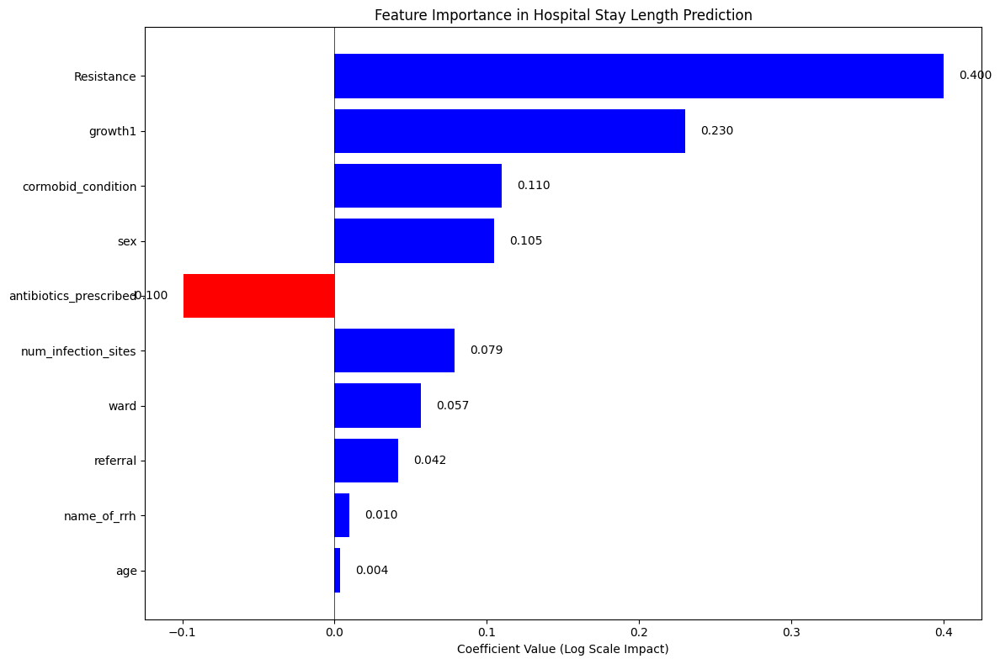


Feature Importance Rankings:
               feature  coefficient  abs_coefficient
            Resistance     0.399992         0.399992
               growth1     0.230165         0.230165
    cormobid_condition     0.109855         0.109855
                   sex     0.104717         0.104717
antibiotics_prescribed    -0.099517         0.099517
   num_infection_sites     0.078726         0.078726
                  ward     0.056766         0.056766
              referral     0.041683         0.041683
           name_of_rrh     0.009674         0.009674
                   age     0.003575         0.003575

Top 5 Most Influential Features:
Resistance: 35.3% influence (increases length of stay)
growth1: 20.3% influence (increases length of stay)
cormobid_condition: 9.7% influence (increases length of stay)
sex: 9.2% influence (increases length of stay)
antibiotics_prescribed: 8.8% influence (decreases length of stay)


In [32]:
# Get feature names and coefficients
feature_importance = pd.DataFrame({
    'feature': X_train.columns,
    'coefficient': huber.coef_
})

# Sort by absolute value of coefficient while keeping the sign
feature_importance['abs_coef'] = abs(feature_importance['coefficient'])
feature_importance = feature_importance.sort_values('abs_coef', ascending=True)

# Create a horizontal bar plot
plt.figure(figsize=(12, 8))
colors = ['red' if c < 0 else 'blue' for c in feature_importance['coefficient']]
bars = plt.barh(feature_importance['feature'], feature_importance['coefficient'], color=colors)

# Add vertical line at x=0
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.5)

# Customize the plot
plt.title('Feature Importance in Hospital Stay Length Prediction')
plt.xlabel('Coefficient Value (Log Scale Impact)')

# Add value labels on the bars
for bar in bars:
    width = bar.get_width()
    label_x = width + (0.01 if width >= 0 else -0.01)
    plt.text(label_x, bar.get_y() + bar.get_height()/2, 
             f'{width:.3f}',
             ha='left' if width >= 0 else 'right', 
             va='center')

plt.tight_layout()
plt.show()

# Print detailed feature importance table
feature_importance['abs_coefficient'] = abs(feature_importance['coefficient'])
feature_importance = feature_importance.sort_values('abs_coefficient', ascending=False)
print("\nFeature Importance Rankings:")
print(feature_importance[['feature', 'coefficient', 'abs_coefficient']].to_string(index=False))

# Calculate percentage influence
total_importance = feature_importance['abs_coefficient'].sum()
feature_importance['influence_percentage'] = (feature_importance['abs_coefficient'] / total_importance * 100)

print("\nTop 5 Most Influential Features:")
top_5 = feature_importance.head()
for _, row in top_5.iterrows():
    direction = "increases" if row['coefficient'] > 0 else "decreases"
    print(f"{row['feature']}: {row['influence_percentage']:.1f}% influence ({direction} length of stay)")

## Hyperparameter tuning

Starting hyperparameter tuning. This may take a while...
Fitting 5 folds for each of 60 candidates, totalling 300 fits
Hyperparameter tuning completed in 4.56 seconds.

Best parameters: {'alpha': 0.1, 'epsilon': 2.25, 'max_iter': 1000}
Best RMSE (negative): -1.1404

----- RESULTS WITH OPTIMIZED HYPERPARAMETERS -----

Original Scale Validation Metrics:
Mean Absolute Error: 30.61
Root Mean Squared Error: 107.14
R-squared Score: -0.0318

Original Scale Test Metrics:
Mean Absolute Error: 24.25
Root Mean Squared Error: 93.88
R-squared Score: -0.0206

Log-space Validation Metrics:
Mean Absolute Error: 0.9424
Root Mean Squared Error: 1.1592
R-squared Score: 0.0963

Log-space Test Metrics:
Mean Absolute Error: 0.7668
Root Mean Squared Error: 1.0014
R-squared Score: 0.0500


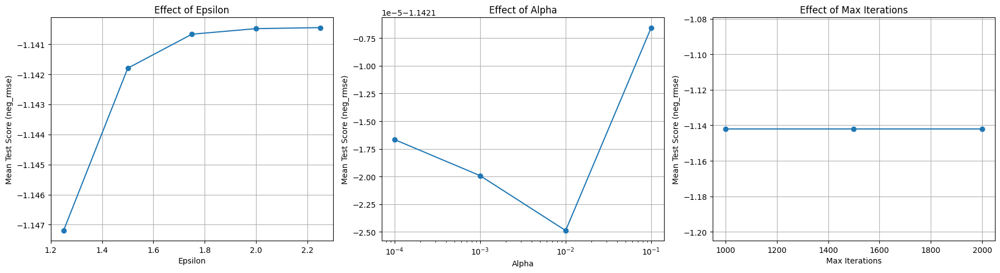

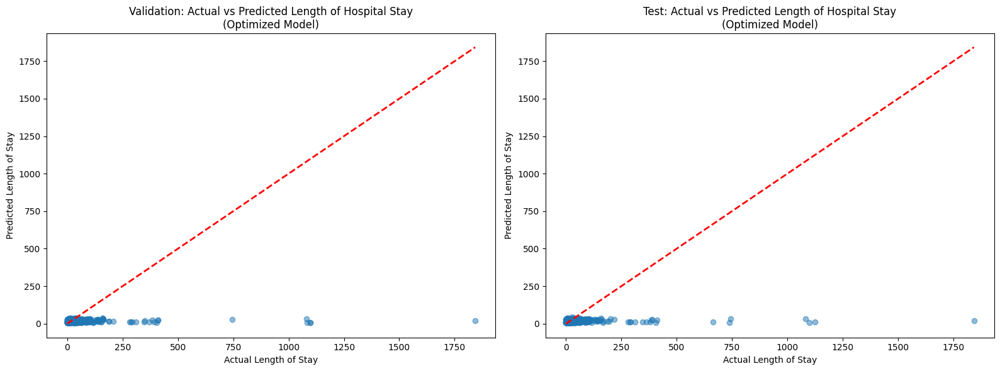

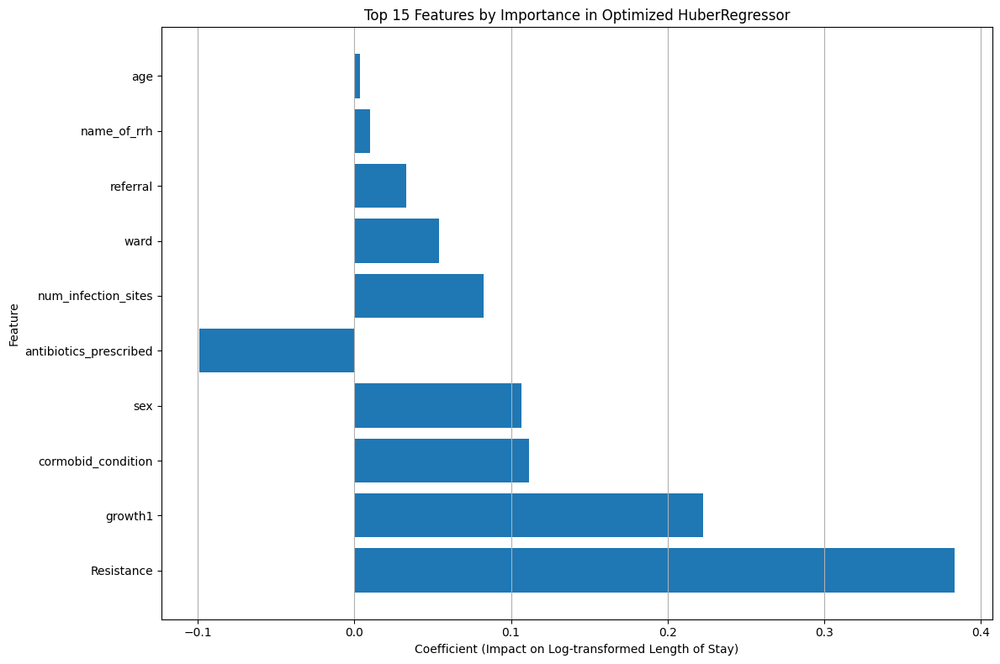

In [33]:
import numpy as np
import pandas as pd
from sklearn.linear_model import HuberRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold
import matplotlib.pyplot as plt
import time

# Apply log transformation to target variables
y_train_log = np.log1p(y_train)  # log1p = log(1+x) to handle zeros
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

# Set up cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Define the parameter grid to search
param_grid = {
    'epsilon': [1.25, 1.5, 1.75, 2.0, 2.25],
    'alpha': [0.0001, 0.001, 0.01, 0.1],
    'max_iter': [1000, 1500, 2000]
}

# Define the scoring metrics
scoring = {
    'neg_mean_absolute_error': 'neg_mean_absolute_error',
    'neg_root_mean_squared_error': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

# Create the base model
huber = HuberRegressor()

print("Starting hyperparameter tuning. This may take a while...")
start_time = time.time()

# Create the GridSearchCV object
grid_search = GridSearchCV(
    estimator=huber,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',  # Primary optimization metric
    cv=cv,
    verbose=1,
    n_jobs=-1  # Use all available cores
)

# Fit the grid search to the data
grid_search.fit(X_train, y_train_log)

end_time = time.time()
print(f"Hyperparameter tuning completed in {end_time - start_time:.2f} seconds.\n")

# Print the best parameters and score
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best RMSE (negative): {grid_search.best_score_:.4f}")

# Train the best model
best_huber = HuberRegressor(**grid_search.best_params_)
best_huber.fit(X_train, y_train_log)

# Make predictions on validation set (in log space)
y_val_pred_log = best_huber.predict(X_val)
# Convert back to original scale
y_val_pred = np.expm1(y_val_pred_log)

# Make predictions on test set (in log space)
y_test_pred_log = best_huber.predict(X_test)
# Convert back to original scale
y_test_pred = np.expm1(y_test_pred_log)

# Calculate metrics on original scale
val_mae = mean_absolute_error(y_val, y_val_pred)
val_mse = mean_squared_error(y_val, y_val_pred)
val_rmse = np.sqrt(val_mse)
val_r2 = r2_score(y_val, y_val_pred)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, y_test_pred)

# Calculate metrics in log space
log_val_mae = mean_absolute_error(y_val_log, y_val_pred_log)
log_val_mse = mean_squared_error(y_val_log, y_val_pred_log)
log_val_rmse = np.sqrt(log_val_mse)
log_val_r2 = r2_score(y_val_log, y_val_pred_log)

log_test_mae = mean_absolute_error(y_test_log, y_test_pred_log)
log_test_mse = mean_squared_error(y_test_log, y_test_pred_log)
log_test_rmse = np.sqrt(log_test_mse)
log_test_r2 = r2_score(y_test_log, y_test_pred_log)

# Print results
print("\n----- RESULTS WITH OPTIMIZED HYPERPARAMETERS -----")
print("\nOriginal Scale Validation Metrics:")
print(f"Mean Absolute Error: {val_mae:.2f}")
print(f"Root Mean Squared Error: {val_rmse:.2f}")
print(f"R-squared Score: {val_r2:.4f}")

print("\nOriginal Scale Test Metrics:")
print(f"Mean Absolute Error: {test_mae:.2f}")
print(f"Root Mean Squared Error: {test_rmse:.2f}")
print(f"R-squared Score: {test_r2:.4f}")

print("\nLog-space Validation Metrics:")
print(f"Mean Absolute Error: {log_val_mae:.4f}")
print(f"Root Mean Squared Error: {log_val_rmse:.4f}")
print(f"R-squared Score: {log_val_r2:.4f}")

print("\nLog-space Test Metrics:")
print(f"Mean Absolute Error: {log_test_mae:.4f}")
print(f"Root Mean Squared Error: {log_test_rmse:.4f}")
print(f"R-squared Score: {log_test_r2:.4f}")

# Visualize the results of hyperparameter tuning
results = pd.DataFrame(grid_search.cv_results_)

# Create plots for each parameter
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Group by epsilon and get mean test score
epsilon_scores = results.groupby('param_epsilon')['mean_test_score'].mean()
axes[0].plot(epsilon_scores.index, epsilon_scores.values, marker='o')
axes[0].set_xlabel('Epsilon')
axes[0].set_ylabel('Mean Test Score (neg_rmse)')
axes[0].set_title('Effect of Epsilon')
axes[0].grid(True)

# Group by alpha and get mean test score
alpha_scores = results.groupby('param_alpha')['mean_test_score'].mean()
axes[1].plot(alpha_scores.index, alpha_scores.values, marker='o')
axes[1].set_xlabel('Alpha')
axes[1].set_ylabel('Mean Test Score (neg_rmse)')
axes[1].set_title('Effect of Alpha')
axes[1].set_xscale('log')
axes[1].grid(True)

# Group by max_iter and get mean test score
max_iter_scores = results.groupby('param_max_iter')['mean_test_score'].mean()
axes[2].plot(max_iter_scores.index, max_iter_scores.values, marker='o')
axes[2].set_xlabel('Max Iterations')
axes[2].set_ylabel('Mean Test Score (neg_rmse)')
axes[2].set_title('Effect of Max Iterations')
axes[2].grid(True)

plt.tight_layout()
plt.show()

# Create scatter plots to visualize predictions vs actual values with optimized model
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Validation set plot
ax1.scatter(y_val, y_val_pred, alpha=0.5)
ax1.plot([y_val.min(), y_val.max()], 
         [y_val.min(), y_val.max()], 
         'r--', lw=2)
ax1.set_xlabel('Actual Length of Stay')
ax1.set_ylabel('Predicted Length of Stay')
ax1.set_title('Validation: Actual vs Predicted Length of Hospital Stay\n(Optimized Model)')

# Test set plot
ax2.scatter(y_test, y_test_pred, alpha=0.5)
ax2.plot([y_test.min(), y_test.max()], 
         [y_test.min(), y_test.max()], 
         'r--', lw=2)
ax2.set_xlabel('Actual Length of Stay')
ax2.set_ylabel('Predicted Length of Stay')
ax2.set_title('Test: Actual vs Predicted Length of Hospital Stay\n(Optimized Model)')

plt.tight_layout()
plt.show()

# Analyze feature importance for the optimized model
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': best_huber.coef_
})

# Sort by absolute coefficient value
feature_importance['Abs_Coefficient'] = np.abs(feature_importance['Coefficient'])
feature_importance = feature_importance.sort_values('Abs_Coefficient', ascending=False)

# Plot feature importance
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'][:15], feature_importance['Coefficient'][:15])
plt.xlabel('Coefficient (Impact on Log-transformed Length of Stay)')
plt.ylabel('Feature')
plt.title('Top 15 Features by Importance in Optimized HuberRegressor')
plt.grid(axis='x')
plt.tight_layout()
plt.show()

Starting grid search optimization...
Fitting 5 folds for each of 50 candidates, totalling 250 fits
[CV] END .............alpha=0.001, epsilon=1.1, max_iter=500; total time=   0.1s
[CV] END .............alpha=0.001, epsilon=1.1, max_iter=500; total time=   0.1s
[CV] END ............alpha=0.001, epsilon=1.1, max_iter=1000; total time=   0.1s
[CV] END .............alpha=0.001, epsilon=1.1, max_iter=500; total time=   0.1s
[CV] END .............alpha=0.001, epsilon=1.1, max_iter=500; total time=   0.1s
[CV] END ............alpha=0.001, epsilon=1.35, max_iter=500; total time=   0.0s
[CV] END .............alpha=0.001, epsilon=1.1, max_iter=500; total time=   0.1s
[CV] END ............alpha=0.001, epsilon=1.1, max_iter=1000; total time=   0.1s
[CV] END ............alpha=0.001, epsilon=1.35, max_iter=500; total time=   0.1s
[CV] END ............alpha=0.001, epsilon=1.35, max_iter=500; total time=   0.1s
[CV] END ............alpha=0.001, epsilon=1.1, max_iter=1000; total time=   0.1s
[CV] END .

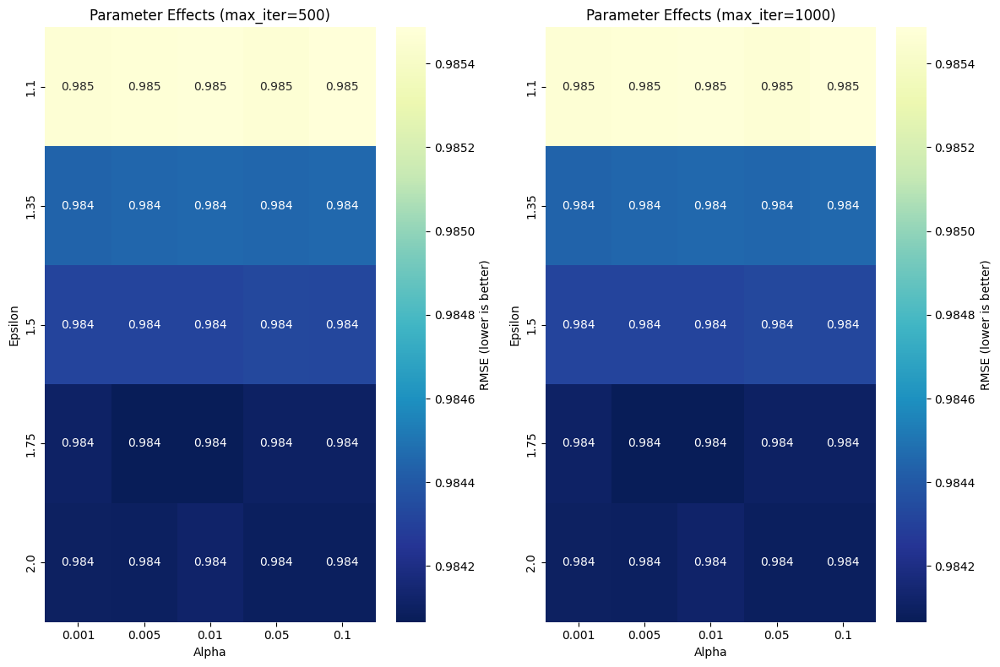

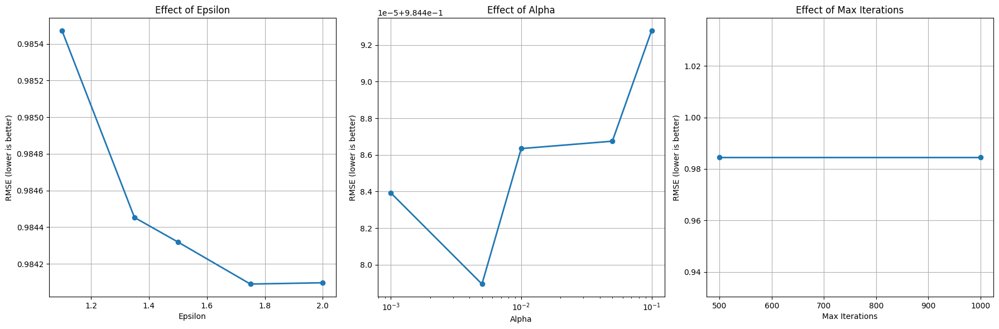

/tmp/ipykernel_84010/1036224788.py:161: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


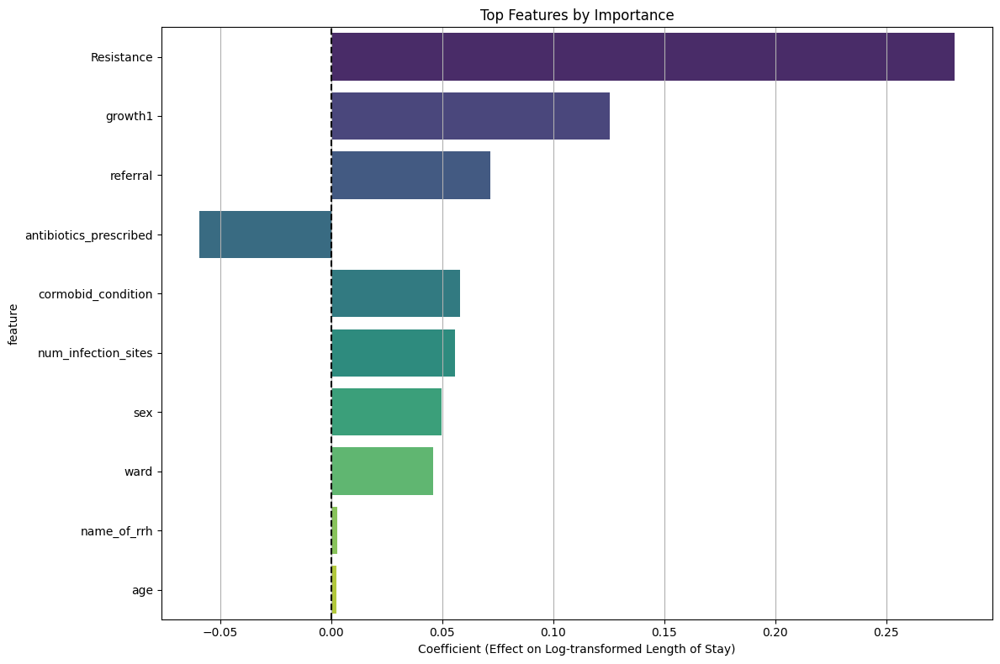

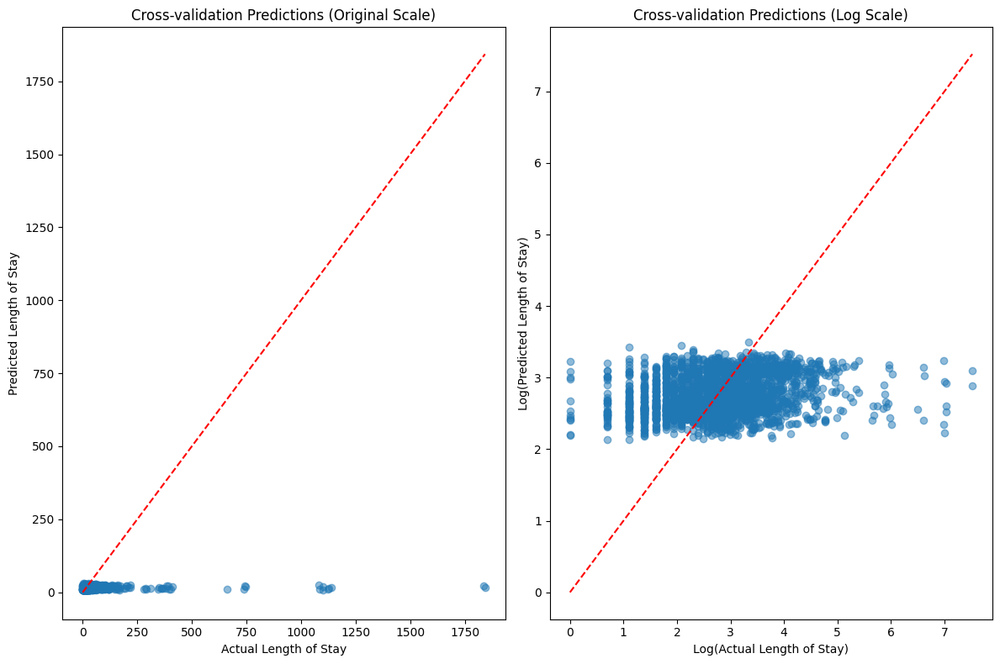


Final Model Performance (Cross-validated):
Original Scale - RMSE: 92.98, MAE: 23.00, R²: -0.0240
Log Scale     - RMSE: 0.9842, MAE: 0.7594, R²: 0.0567


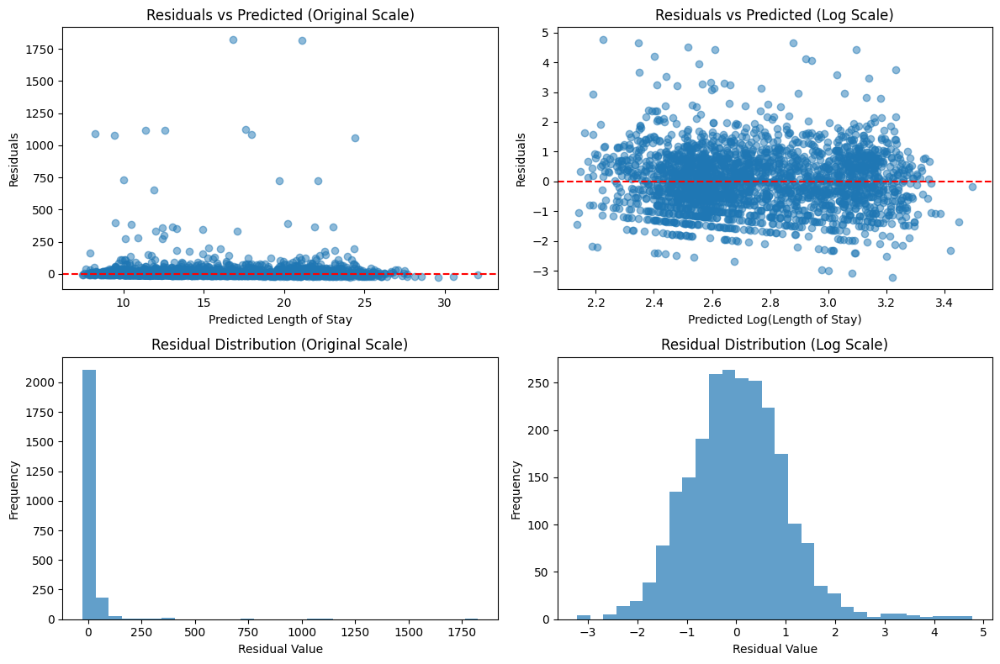

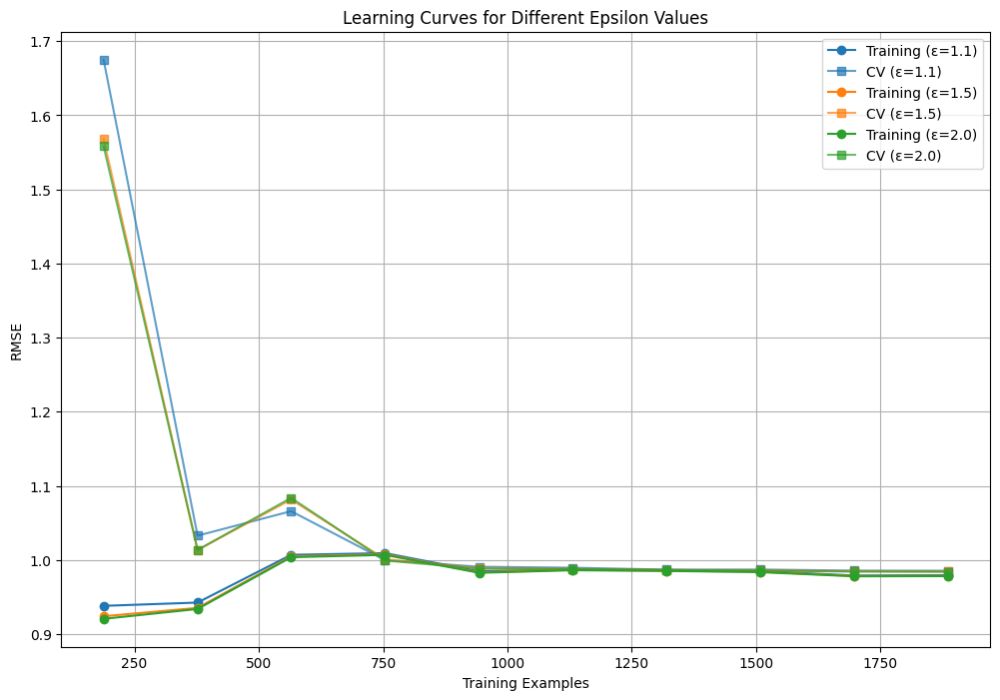


Grid search optimization completed. All visualizations saved as PNG files.


In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import HuberRegressor
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, cross_val_predict
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import time

# Prepare the data (using log transform as before)
X = data.drop(columns='length_hosp_stay')
y = np.log1p(data['length_hosp_stay'])

# Define parameter grid (expanded)
param_grid = {
    'epsilon': [1.1, 1.35, 1.5, 1.75, 2.0],
    'alpha': [0.001, 0.005, 0.01, 0.05, 0.1],
    'max_iter': [500, 1000]  # Added another option
}

print("Starting grid search optimization...")
start_time = time.time()

# Set up cross-validation strategy
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Define multiple scoring metrics
scoring = {
    'neg_mse': 'neg_mean_squared_error',
    'neg_mae': 'neg_mean_absolute_error',
    'r2': 'r2'
}

# Perform grid search with cross-validation and multiple metrics
grid_search = GridSearchCV(
    HuberRegressor(),
    param_grid,
    cv=cv,
    scoring=scoring,
    refit='neg_mse',  # Primary metric for selecting best model
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

# Fit the grid search
grid_search.fit(X, y)

end_time = time.time()
print(f"\nGrid search completed in {end_time - start_time:.2f} seconds")

# Print the best parameters and score
print("\nBest parameters:", grid_search.best_params_)
print("Best cross-validation RMSE:", np.sqrt(-grid_search.best_score_))

# Get detailed results
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results = cv_results.sort_values('rank_test_neg_mse')

# Compute RMSE for display
cv_results['test_rmse'] = np.sqrt(-cv_results['mean_test_neg_mse'])
cv_results['train_rmse'] = np.sqrt(-cv_results['mean_train_neg_mse'])
cv_results['test_mae'] = -cv_results['mean_test_neg_mae']

# Print top 5 parameter combinations
print("\nTop 5 parameter combinations:")
top_5 = cv_results[['params', 'test_rmse', 'test_mae', 'mean_test_r2', 'std_test_neg_mse']].head()
print(top_5)

# Calculate overfitting indicators
cv_results['overfitting'] = cv_results['train_rmse'] - cv_results['test_rmse']

# Save results to CSV for reference
cv_results.to_csv('huber_grid_search_results.csv', index=False)
print("Full results saved to 'huber_grid_search_results.csv'")

# Create a final model with the best parameters
print("\nTraining final model with best parameters...")
best_model = HuberRegressor(**grid_search.best_params_)
best_model.fit(X, y)

# Get feature importances
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'coefficient': best_model.coef_
})
feature_importance['abs_coefficient'] = np.abs(feature_importance['coefficient'])
feature_importance = feature_importance.sort_values('abs_coefficient', ascending=False)

print("\nTop 10 Feature Importances:")
print(feature_importance.head(10))

# ==== VISUALIZATIONS ====

# 1. Plot parameter effects - Heatmap of epsilon vs alpha
plt.figure(figsize=(12, 8))

# Create separate subplot for each max_iter value
max_iters = sorted(param_grid['max_iter'])
num_max_iters = len(max_iters)

for i, max_iter in enumerate(max_iters):
    plt.subplot(1, num_max_iters, i+1)
    
    # Filter results for this max_iter
    iter_results = cv_results[cv_results['param_max_iter'] == max_iter]
    
    # Create pivot table
    pivot_data = iter_results.pivot_table(
        values='test_rmse',
        index='param_epsilon',
        columns='param_alpha'
    )
    
    # Plot heatmap
    sns.heatmap(pivot_data, annot=True, fmt='.3f', cmap='YlGnBu_r',
                cbar_kws={'label': 'RMSE (lower is better)'})
    plt.title(f'Parameter Effects (max_iter={max_iter})')
    plt.xlabel('Alpha')
    plt.ylabel('Epsilon')

plt.tight_layout()
plt.savefig('huber_parameter_heatmap.png')
plt.show()

# 2. Line plots for each parameter
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Group by epsilon and get mean performance
epsilon_scores = cv_results.groupby('param_epsilon')['test_rmse'].mean()
axes[0].plot(epsilon_scores.index, epsilon_scores, marker='o', linewidth=2)
axes[0].set_xlabel('Epsilon')
axes[0].set_ylabel('RMSE (lower is better)')
axes[0].set_title('Effect of Epsilon')
axes[0].grid(True)

# Group by alpha and get mean performance
alpha_scores = cv_results.groupby('param_alpha')['test_rmse'].mean()
axes[1].plot(alpha_scores.index, alpha_scores, marker='o', linewidth=2)
axes[1].set_xlabel('Alpha')
axes[1].set_ylabel('RMSE (lower is better)')
axes[1].set_title('Effect of Alpha')
axes[1].set_xscale('log')
axes[1].grid(True)

# Group by max_iter and get mean performance
max_iter_scores = cv_results.groupby('param_max_iter')['test_rmse'].mean()
axes[2].plot(max_iter_scores.index, max_iter_scores, marker='o', linewidth=2)
axes[2].set_xlabel('Max Iterations')
axes[2].set_ylabel('RMSE (lower is better)')
axes[2].set_title('Effect of Max Iterations')
axes[2].grid(True)

plt.tight_layout()
plt.savefig('huber_parameter_effects.png')
plt.show()

# 3. Feature importance visualization
plt.figure(figsize=(12, 8))
top_n = 15  # Show top 15 features
sns.barplot(
    x='coefficient', 
    y='feature', 
    data=feature_importance.head(top_n),
    palette='viridis'
)
plt.title('Top Features by Importance')
plt.xlabel('Coefficient (Effect on Log-transformed Length of Stay)')
plt.axvline(x=0, color='k', linestyle='--')
plt.grid(axis='x')
plt.tight_layout()
plt.savefig('huber_feature_importance.png')
plt.show()

# 4. Cross-validation prediction performance
y_pred_cv = cross_val_predict(best_model, X, y, cv=cv)
y_pred_original = np.expm1(y_pred_cv)
y_original = np.expm1(y)

plt.figure(figsize=(12, 8))

# Plot in original scale
plt.subplot(1, 2, 1)
plt.scatter(y_original, y_pred_original, alpha=0.5)
plt.plot([min(y_original), max(y_original)], [min(y_original), max(y_original)], 'r--')
plt.xlabel('Actual Length of Stay')
plt.ylabel('Predicted Length of Stay')
plt.title('Cross-validation Predictions (Original Scale)')

# Plot in log scale
plt.subplot(1, 2, 2)
plt.scatter(y, y_pred_cv, alpha=0.5)
plt.plot([min(y), max(y)], [min(y), max(y)], 'r--')
plt.xlabel('Log(Actual Length of Stay)')
plt.ylabel('Log(Predicted Length of Stay)')
plt.title('Cross-validation Predictions (Log Scale)')

plt.tight_layout()
plt.savefig('huber_prediction_performance.png')
plt.show()

# 5. Calculate and display key metrics
rmse_original = np.sqrt(mean_squared_error(y_original, y_pred_original))
mae_original = mean_absolute_error(y_original, y_pred_original)
r2_original = r2_score(y_original, y_pred_original)

rmse_log = np.sqrt(mean_squared_error(y, y_pred_cv))
mae_log = mean_absolute_error(y, y_pred_cv)
r2_log = r2_score(y, y_pred_cv)

print("\nFinal Model Performance (Cross-validated):")
print(f"Original Scale - RMSE: {rmse_original:.2f}, MAE: {mae_original:.2f}, R²: {r2_original:.4f}")
print(f"Log Scale     - RMSE: {rmse_log:.4f}, MAE: {mae_log:.4f}, R²: {r2_log:.4f}")

# 6. Analyze residuals
residuals_log = y - y_pred_cv
residuals_original = y_original - y_pred_original

plt.figure(figsize=(12, 8))

# Residuals in original scale
plt.subplot(2, 2, 1)
plt.scatter(y_pred_original, residuals_original, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Length of Stay')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted (Original Scale)')

# Residuals in log scale
plt.subplot(2, 2, 2)
plt.scatter(y_pred_cv, residuals_log, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Log(Length of Stay)')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted (Log Scale)')

# Histogram of residuals (original scale)
plt.subplot(2, 2, 3)
plt.hist(residuals_original, bins=30, alpha=0.7)
plt.xlabel('Residual Value')
plt.ylabel('Frequency')
plt.title('Residual Distribution (Original Scale)')

# Histogram of residuals (log scale)
plt.subplot(2, 2, 4)
plt.hist(residuals_log, bins=30, alpha=0.7)
plt.xlabel('Residual Value')
plt.ylabel('Frequency')
plt.title('Residual Distribution (Log Scale)')

plt.tight_layout()
plt.savefig('huber_residual_analysis.png')
plt.show()

# 7. Learning curves - compare different epsilon values
from sklearn.model_selection import learning_curve

# Get best alpha and max_iter
best_alpha = grid_search.best_params_['alpha']
best_max_iter = grid_search.best_params_['max_iter']

# Test different epsilon values
epsilon_values = [1.1, 1.5, 2.0]
plt.figure(figsize=(12, 8))

for i, epsilon in enumerate(epsilon_values):
    model = HuberRegressor(epsilon=epsilon, alpha=best_alpha, max_iter=best_max_iter)
    
    train_sizes, train_scores, test_scores = learning_curve(
        model, X, y, cv=cv, scoring='neg_mean_squared_error',
        train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
    )
    
    train_rmse = np.sqrt(-train_scores.mean(axis=1))
    test_rmse = np.sqrt(-test_scores.mean(axis=1))
    
    plt.plot(train_sizes, train_rmse, 'o-', color=f'C{i}', label=f'Training (ε={epsilon})')
    plt.plot(train_sizes, test_rmse, 's-', color=f'C{i}', alpha=0.7, label=f'CV (ε={epsilon})')

plt.xlabel('Training Examples')
plt.ylabel('RMSE')
plt.title('Learning Curves for Different Epsilon Values')
plt.legend(loc='best')
plt.grid(True)
plt.savefig('huber_learning_curves.png')
plt.show()

print("\nGrid search optimization completed. All visualizations saved as PNG files.")

# Random Forest Regressor


Training set: 3772 samples
Validation set: 944 samples
Test set: 1179 samples

Training Random Forest model...
Cross-validation R2 Score: 0.3405

Validation Metrics:
Mean Absolute Error: 26.53
Root Mean Squared Error: 90.64
R-squared Score: 0.2617


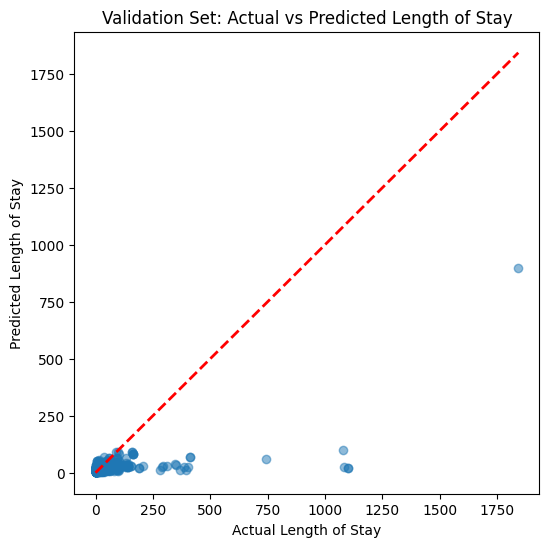


Test Metrics:
Mean Absolute Error: 21.40
Root Mean Squared Error: 78.64
R-squared Score: 0.2838


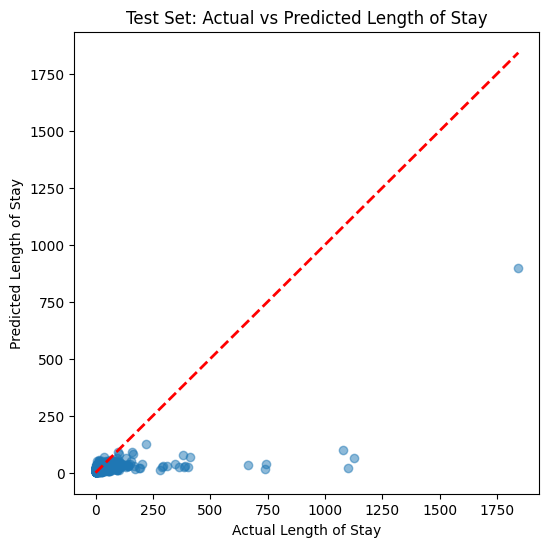

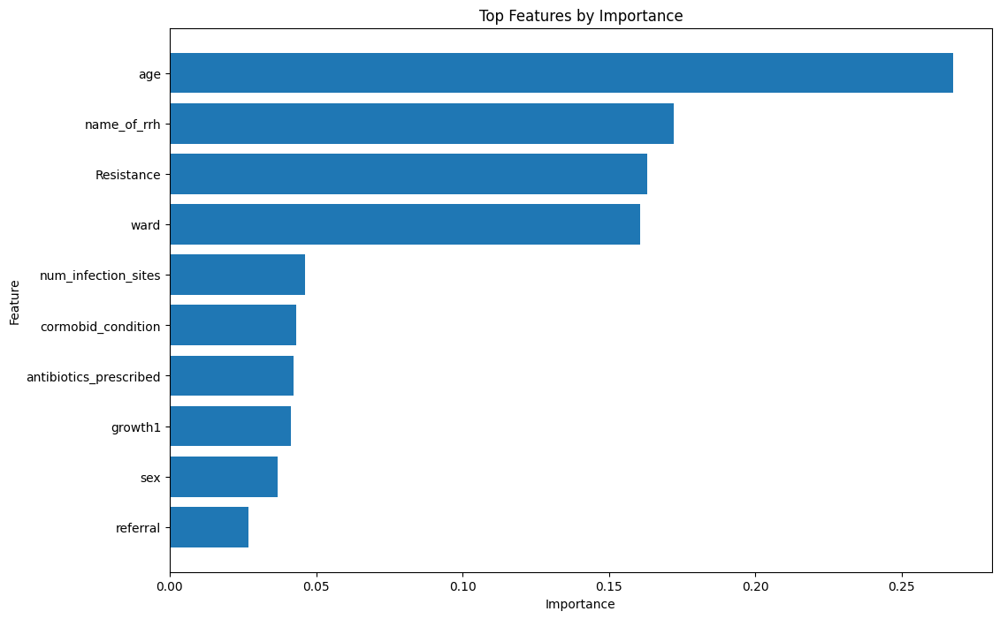

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Log-transform the target variable
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Define fixed hyperparameters (without optimization)
rf_params = {
    'n_estimators': 1000,
    'max_depth': 8,
    'min_samples_split': 10,
    'min_samples_leaf': 4,
    'max_features': 0.8,
    'bootstrap': False,
    'random_state': 42
}

# Train the model
print("\nTraining Random Forest model...")
rf = RandomForestRegressor(**rf_params)
rf.fit(X_train, y_train_log)

# Cross-validation on training set
cv_scores = cross_val_score(rf, X_train, y_train_log, cv=5, scoring='r2')
print(f"Cross-validation R2 Score: {np.mean(cv_scores):.4f}")

# Evaluate model on validation and test sets
for X_set, y_set_log, y_set, label in [(X_val, y_val_log, y_val, 'Validation'), (X_test, y_test_log, y_test, 'Test')]:
    y_pred_log = rf.predict(X_set)
    y_pred = np.expm1(y_pred_log)  # Convert back from log scale
    y_actual = np.expm1(y_set_log)  # Convert back for comparison

    # Compute metrics
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    print(f"\n{label} Metrics:")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}")
    print(f"R-squared Score: {r2:.4f}")

    # Scatter plot for actual vs. predicted values
    plt.figure(figsize=(6, 6))
    plt.scatter(y_actual, y_pred, alpha=0.5)
    plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
    plt.xlabel('Actual Length of Stay')
    plt.ylabel('Predicted Length of Stay')
    plt.title(f'{label} Set: Actual vs Predicted Length of Stay')
    plt.show()

# Feature importance
feature_importance = pd.DataFrame({'Feature': X_train.columns, 'Importance': rf.feature_importances_}).sort_values('Importance', ascending=False)

# Plot top 20 features
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'][:20], feature_importance['Importance'][:20])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top Features by Importance')
plt.gca().invert_yaxis()  # Highest importance at top
plt.show()

Training set: 3772 samples
Validation set: 944 samples
Test set: 1179 samples
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best Parameters Found: {'n_estimators': 1500, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 0.8, 'max_depth': 12, 'bootstrap': False}
Cross-validation R2 Score: 0.5103

Validation Metrics:
Mean Absolute Error: 20.82
Root Mean Squared Error: 70.88
R-squared Score: 0.5485


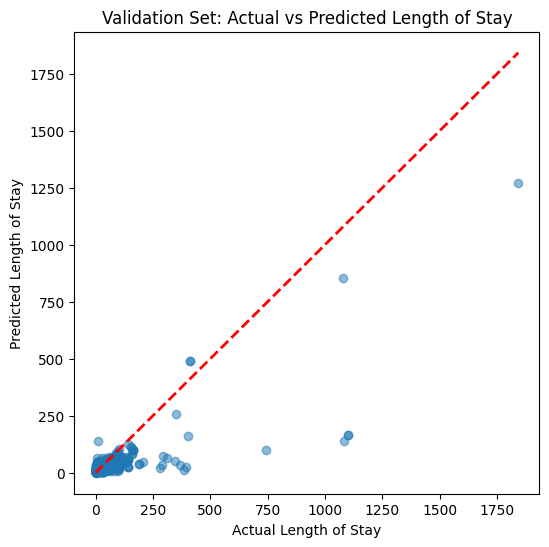


Test Metrics:
Mean Absolute Error: 16.92
Root Mean Squared Error: 60.97
R-squared Score: 0.5695


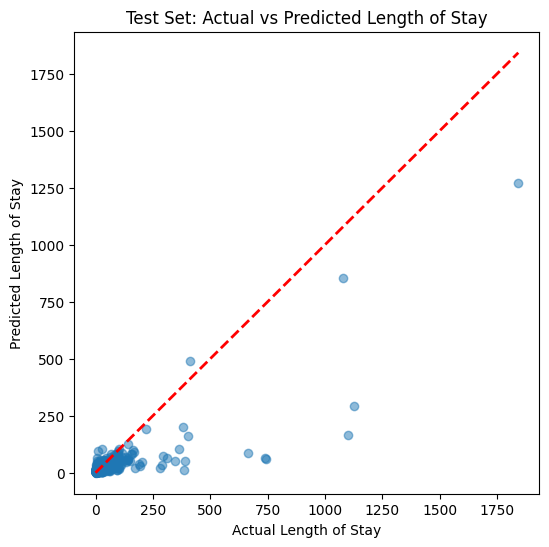

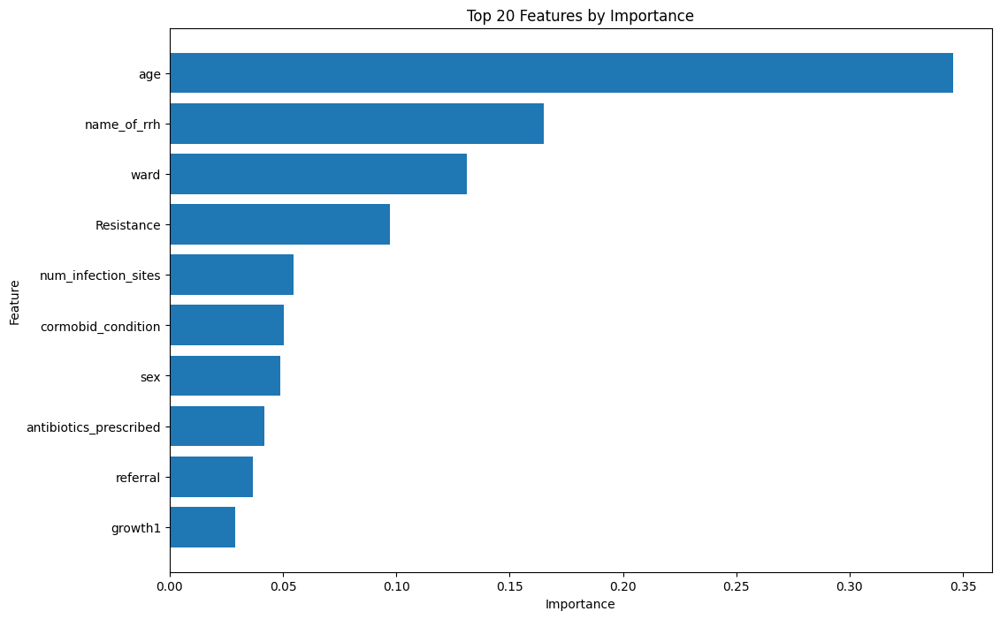

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Log-transform the target variable
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Define hyperparameter grid for tuning
param_grid = {
    'n_estimators': [500, 1000, 1500],
    'max_depth': [6, 8, 10, 12],
    'min_samples_split': [5, 10, 15],
    'min_samples_leaf': [2, 4, 6],
    'max_features': [0.6, 0.8, 'sqrt'],
    'bootstrap': [True, False]
}

# Initialize Random Forest model
rf = RandomForestRegressor(random_state=42)

# Perform Randomized Search Cross Validation
random_search = RandomizedSearchCV(
    rf, param_grid, n_iter=15, cv=3, scoring='neg_mean_absolute_error', 
    random_state=42, n_jobs=-1, verbose=1
)
random_search.fit(X_train, y_train_log)

# Get the best model from random search
best_rf = random_search.best_estimator_
print("\nBest Parameters Found:", random_search.best_params_)

# Cross-validation on training set
cv_scores = cross_val_score(best_rf, X_train, y_train_log, cv=5, scoring='r2')
print(f"Cross-validation R2 Score: {np.mean(cv_scores):.4f}")

# Evaluate model on validation and test sets
for X_set, y_set_log, y_set, label in [(X_val, y_val_log, y_val, 'Validation'), (X_test, y_test_log, y_test, 'Test')]:
    y_pred_log = best_rf.predict(X_set)
    y_pred = np.expm1(y_pred_log)  # Convert back from log scale
    y_actual = np.expm1(y_set_log)  # Convert back for comparison

    # Compute metrics
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    print(f"\n{label} Metrics:")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}")
    print(f"R-squared Score: {r2:.4f}")

    # Scatter plot for actual vs. predicted values
    plt.figure(figsize=(6, 6))
    plt.scatter(y_actual, y_pred, alpha=0.5)
    plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
    plt.xlabel('Actual Length of Stay')
    plt.ylabel('Predicted Length of Stay')
    plt.title(f'{label} Set: Actual vs Predicted Length of Stay')
    plt.show()

# Feature importance
feature_importance = pd.DataFrame({'Feature': X_train.columns, 'Importance': best_rf.feature_importances_}).sort_values('Importance', ascending=False)

# Plot top 20 features
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'][:20], feature_importance['Importance'][:20])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 20 Features by Importance')
plt.gca().invert_yaxis()  # Highest importance at top
plt.show()


Training set: 3772 samples
Validation set: 944 samples
Test set: 1179 samples
Fitting 3 folds for each of 32 candidates, totalling 96 fits

Best Parameters Found: {'bootstrap': False, 'max_depth': 12, 'max_features': 0.8, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 2000, 'random_state': 42}
Cross-validation R2 Score: 0.5791

Validation Metrics:
Mean Absolute Error: 17.64
Root Mean Squared Error: 61.92
R-squared Score: 0.6554


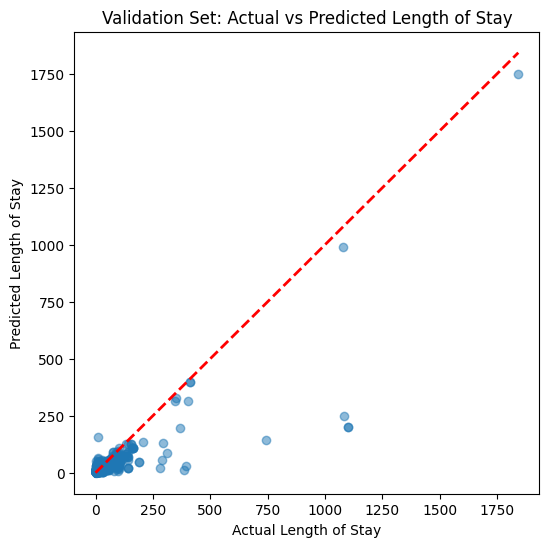


Test Metrics:
Mean Absolute Error: 13.87
Root Mean Squared Error: 48.68
R-squared Score: 0.7255


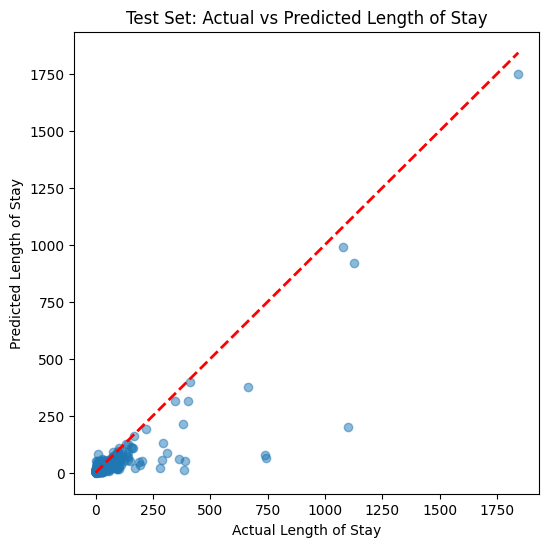

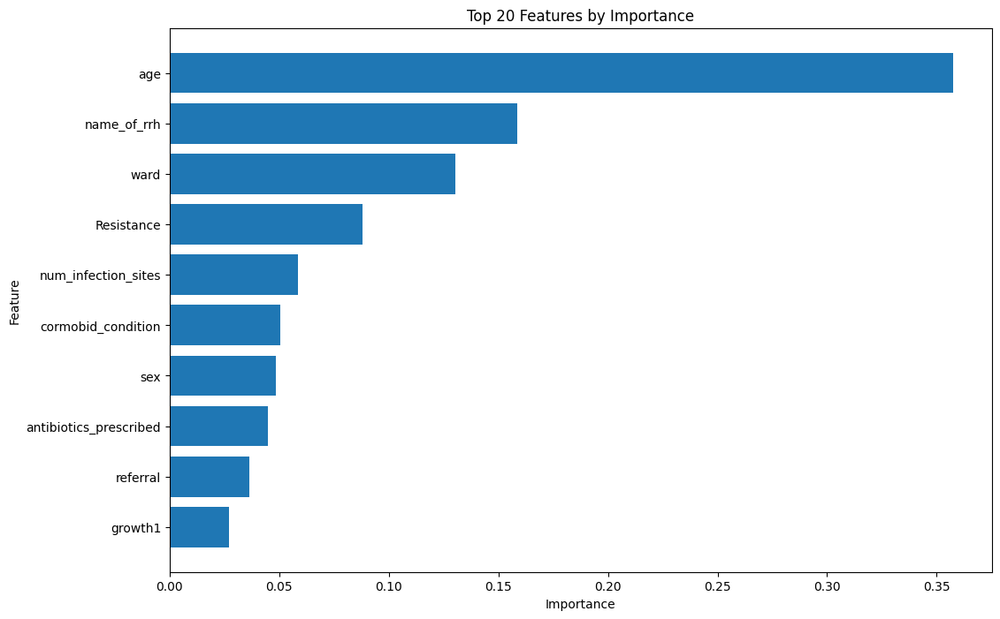

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Log-transform the target variable
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Define hyperparameter grid for tuning
param_grid = {
    'n_estimators': [500, 2000],
    'max_depth': [4, 12],
    'min_samples_split': [5, 12],
    'min_samples_leaf': [2, 4],
    'max_features': [0.6, 0.8],
    'random_state': [42],
    'bootstrap': [False]
}

# Initialize Random Forest model
rf = RandomForestRegressor(random_state=42)

# Perform Grid Search Cross Validation
grid_search = GridSearchCV(
    rf, param_grid, cv=3, scoring='neg_mean_absolute_error', 
    n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train_log)

# Get the best model from grid search
best_rf = grid_search.best_estimator_
print("\nBest Parameters Found:", grid_search.best_params_)

# Cross-validation on training set
cv_scores = cross_val_score(best_rf, X_train, y_train_log, cv=5, scoring='r2')
print(f"Cross-validation R2 Score: {np.mean(cv_scores):.4f}")

# Evaluate model on validation and test sets
for X_set, y_set_log, y_set, label in [(X_val, y_val_log, y_val, 'Validation'), (X_test, y_test_log, y_test, 'Test')]:
    y_pred_log = best_rf.predict(X_set)
    y_pred = np.expm1(y_pred_log)  # Convert back from log scale
    y_actual = np.expm1(y_set_log)  # Convert back for comparison

    # Compute metrics
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    print(f"\n{label} Metrics:")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}")
    print(f"R-squared Score: {r2:.4f}")

    # Scatter plot for actual vs. predicted values
    plt.figure(figsize=(6, 6))
    plt.scatter(y_actual, y_pred, alpha=0.5)
    plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
    plt.xlabel('Actual Length of Stay')
    plt.ylabel('Predicted Length of Stay')
    plt.title(f'{label} Set: Actual vs Predicted Length of Stay')
    plt.show()

# Feature importance
feature_importance = pd.DataFrame({'Feature': X_train.columns, 'Importance': best_rf.feature_importances_}).sort_values('Importance', ascending=False)

# Plot top 20 features
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'][:20], feature_importance['Importance'][:20])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 20 Features by Importance')
plt.gca().invert_yaxis()  # Highest importance at top
plt.show()

# GradientBoostingRegressor

Training set: 3772 samples
Validation set: 944 samples
Test set: 1179 samples

Training Gradient Boosting model...
Cross-validation R2 Score: 0.5854

Validation Metrics:
Mean Absolute Error: 17.30
Root Mean Squared Error: 67.34
R-squared Score: 0.5924


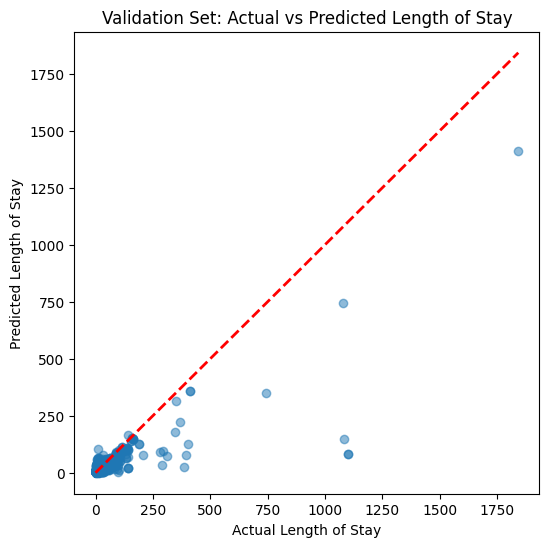


Test Metrics:
Mean Absolute Error: 13.91
Root Mean Squared Error: 54.28
R-squared Score: 0.6587


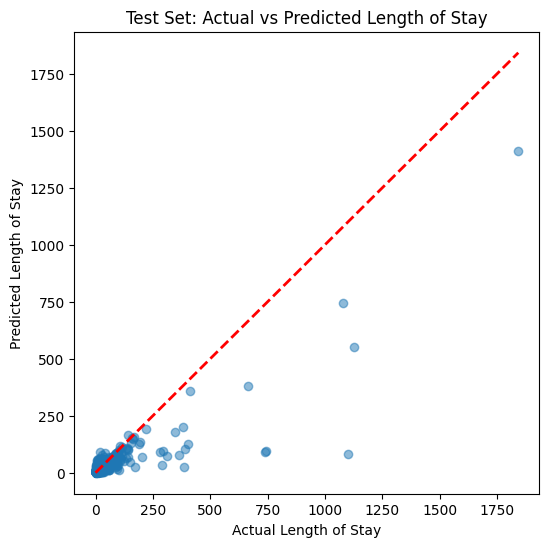

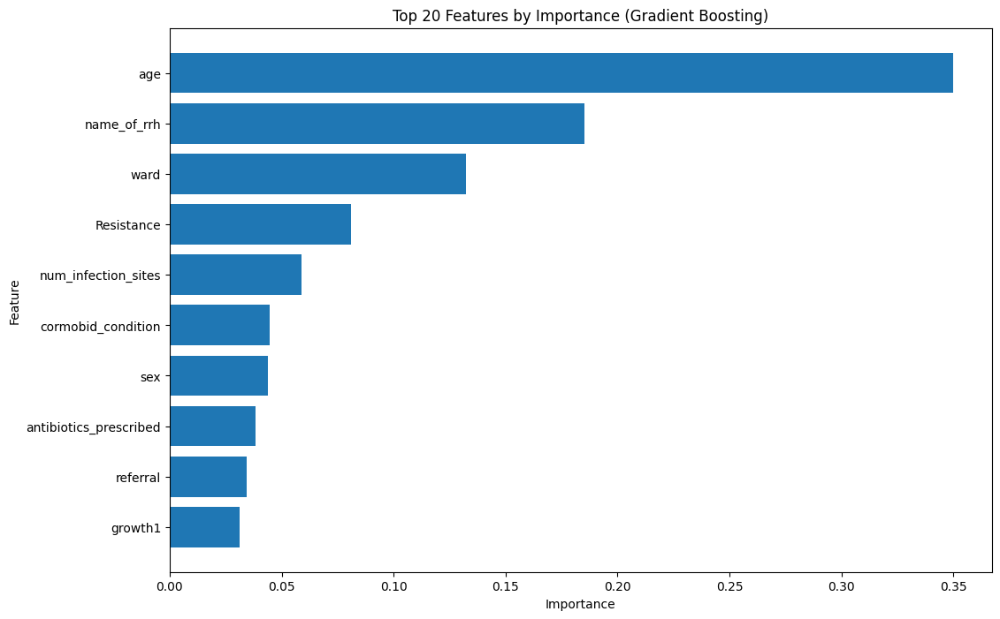

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Log-transform the target variable
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Define fixed hyperparameters (without optimization)
gbr_params = {
    'n_estimators': 1000,
    'learning_rate': 0.05,
    'max_depth': 5,
    'min_samples_split': 10,
    'min_samples_leaf': 4,
    'subsample': 0.8,
    'random_state': 42
}

# Train the model
print("\nTraining Gradient Boosting model...")
gbr = GradientBoostingRegressor(**gbr_params)
gbr.fit(X_train, y_train_log)

# Cross-validation on training set
cv_scores = cross_val_score(gbr, X_train, y_train_log, cv=5, scoring='r2')
print(f"Cross-validation R2 Score: {np.mean(cv_scores):.4f}")

# Evaluate model on validation and test sets
for X_set, y_set_log, y_set, label in [(X_val, y_val_log, y_val, 'Validation'), (X_test, y_test_log, y_test, 'Test')]:
    y_pred_log = gbr.predict(X_set)
    y_pred = np.expm1(y_pred_log)  # Convert back from log scale
    y_actual = np.expm1(y_set_log)  # Convert back for comparison

    # Compute metrics
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    print(f"\n{label} Metrics:")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}")
    print(f"R-squared Score: {r2:.4f}")

    # Scatter plot for actual vs. predicted values
    plt.figure(figsize=(6, 6))
    plt.scatter(y_actual, y_pred, alpha=0.5)
    plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
    plt.xlabel('Actual Length of Stay')
    plt.ylabel('Predicted Length of Stay')
    plt.title(f'{label} Set: Actual vs Predicted Length of Stay')
    plt.show()

# Feature importance
feature_importance = pd.DataFrame({'Feature': X_train.columns, 'Importance': gbr.feature_importances_}).sort_values('Importance', ascending=False)

# Plot top 20 features
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'][:20], feature_importance['Importance'][:20])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 20 Features by Importance (Gradient Boosting)')
plt.gca().invert_yaxis()  # Highest importance at top
plt.show()


Training set: 3772 samples
Validation set: 944 samples
Test set: 1179 samples

Optimizing hyperparameters using Randomized Search...

Best Parameters: {'learning_rate': 0.19533177315875885, 'max_depth': 9, 'min_samples_leaf': 9, 'min_samples_split': 19, 'n_estimators': 955, 'subsample': 0.8281775897621597}
Cross-validation R2 Score: 0.6219

Validation Metrics:
Mean Absolute Error: 7.60
Root Mean Squared Error: 23.57
R-squared Score: 0.9501


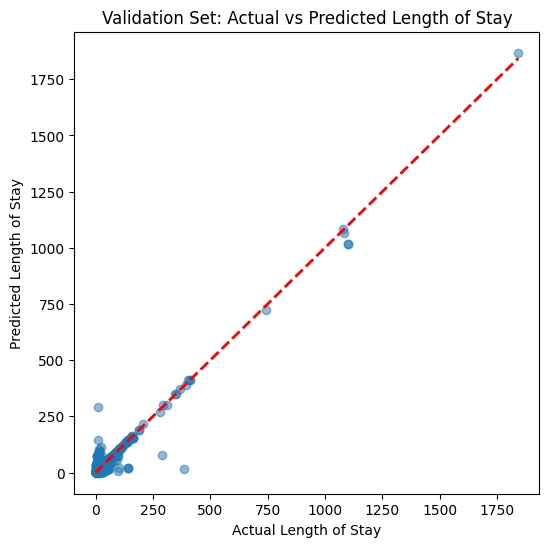


Test Metrics:
Mean Absolute Error: 4.61
Root Mean Squared Error: 18.43
R-squared Score: 0.9606


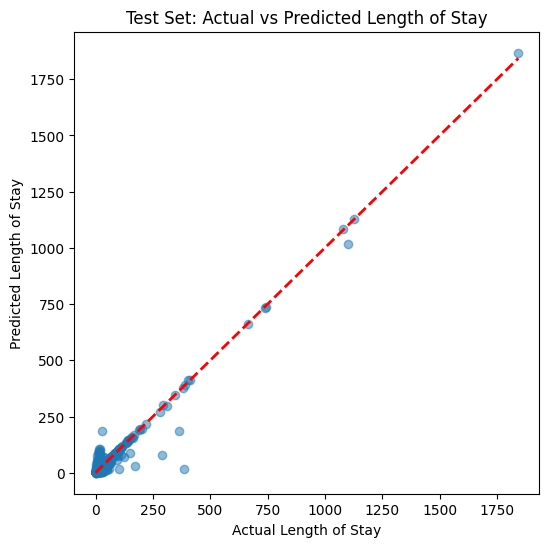

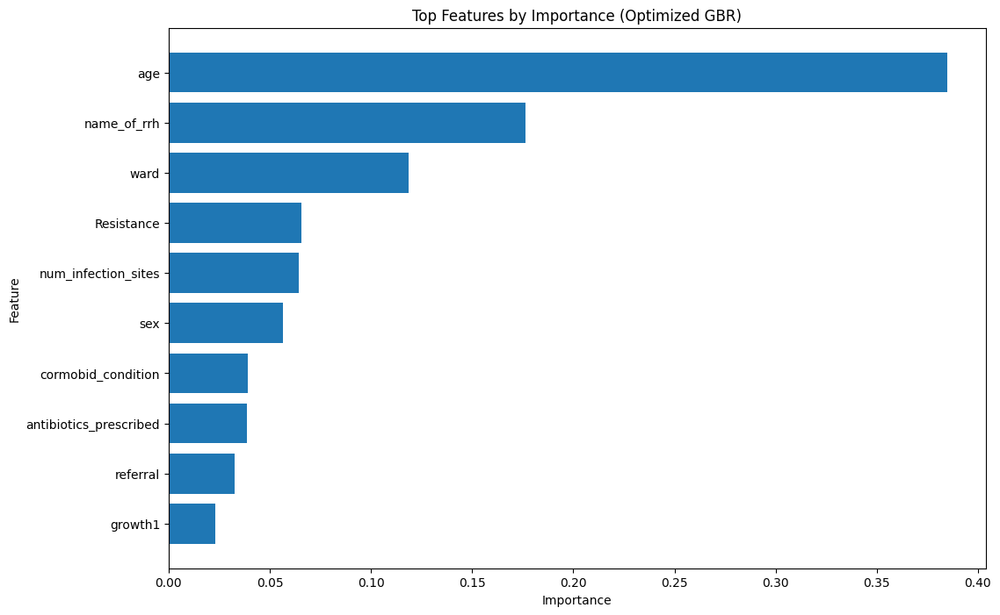

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import uniform, randint

# Log-transform the target variable
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Define the hyperparameter grid
param_dist = {
    'n_estimators': randint(500, 1500),
    'learning_rate': uniform(0.01, 0.2),
    'max_depth': randint(3, 10),
    'min_samples_split': randint(5, 20),
    'min_samples_leaf': randint(2, 10),
    'subsample': uniform(0.6, 0.4),
}

# Initialize model
gbr = GradientBoostingRegressor(random_state=42)

# Perform Randomized Search
random_search = RandomizedSearchCV(
    gbr, param_dist, 
    n_iter=20, cv=3, scoring='neg_mean_absolute_error', 
    random_state=42, n_jobs=-1
)
print("\nOptimizing hyperparameters using Randomized Search...")
random_search.fit(X_train, y_train_log)

# Retrieve best model
best_gbr = random_search.best_estimator_
print("\nBest Parameters:", random_search.best_params_)

# Cross-validation on training set
cv_scores = cross_val_score(best_gbr, X_train, y_train_log, cv=5, scoring='r2')
print(f"Cross-validation R2 Score: {np.mean(cv_scores):.4f}")

# Evaluate model on validation and test sets
for X_set, y_set_log, y_set, label in [(X_val, y_val_log, y_val, 'Validation'), (X_test, y_test_log, y_test, 'Test')]:
    y_pred_log = best_gbr.predict(X_set)
    y_pred = np.expm1(y_pred_log)  # Convert back from log scale
    y_actual = np.expm1(y_set_log)  # Convert back for comparison

    # Compute metrics
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    print(f"\n{label} Metrics:")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}")
    print(f"R-squared Score: {r2:.4f}")

    # Scatter plot for actual vs. predicted values
    plt.figure(figsize=(6, 6))
    plt.scatter(y_actual, y_pred, alpha=0.5)
    plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
    plt.xlabel('Actual Length of Stay')
    plt.ylabel('Predicted Length of Stay')
    plt.title(f'{label} Set: Actual vs Predicted Length of Stay')
    plt.show()

# Feature importance
feature_importance = pd.DataFrame({'Feature': X_train.columns, 'Importance': best_gbr.feature_importances_}).sort_values('Importance', ascending=False)

# Plot top 20 features
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'][:20], feature_importance['Importance'][:20])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top Features by Importance (Optimized GBR)')
plt.gca().invert_yaxis()  # Highest importance at top
plt.show()


Training set: 3772 samples
Validation set: 944 samples
Test set: 1179 samples

Optimizing hyperparameters using Grid Search...
Fitting 3 folds for each of 216 candidates, totalling 648 fits
[CV] END learning_rate=0.001, max_depth=3, min_samples_leaf=2, min_samples_split=5, n_estimators=500, random_state=42, subsample=0.6; total time=   1.2s
[CV] END learning_rate=0.001, max_depth=3, min_samples_leaf=2, min_samples_split=5, n_estimators=500, random_state=42, subsample=0.6; total time=   1.2s
[CV] END learning_rate=0.001, max_depth=3, min_samples_leaf=2, min_samples_split=5, n_estimators=500, random_state=42, subsample=1.0; total time=   1.4s
[CV] END learning_rate=0.001, max_depth=3, min_samples_leaf=2, min_samples_split=5, n_estimators=500, random_state=42, subsample=1.0; total time=   1.4s
[CV] END learning_rate=0.001, max_depth=3, min_samples_leaf=2, min_samples_split=5, n_estimators=500, random_state=42, subsample=0.8; total time=   1.5s
[CV] END learning_rate=0.001, max_depth=3, mi

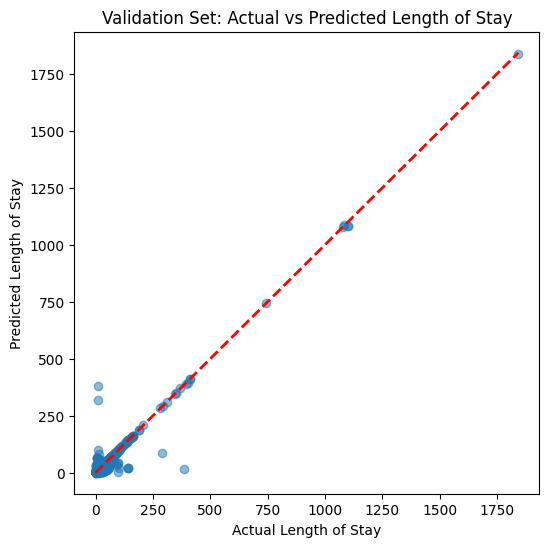


Test Metrics:
Mean Absolute Error: 3.79
Root Mean Squared Error: 17.09
R-squared Score: 0.9662


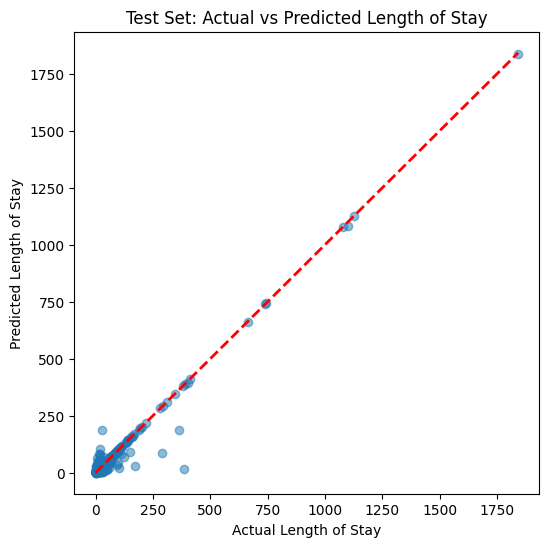

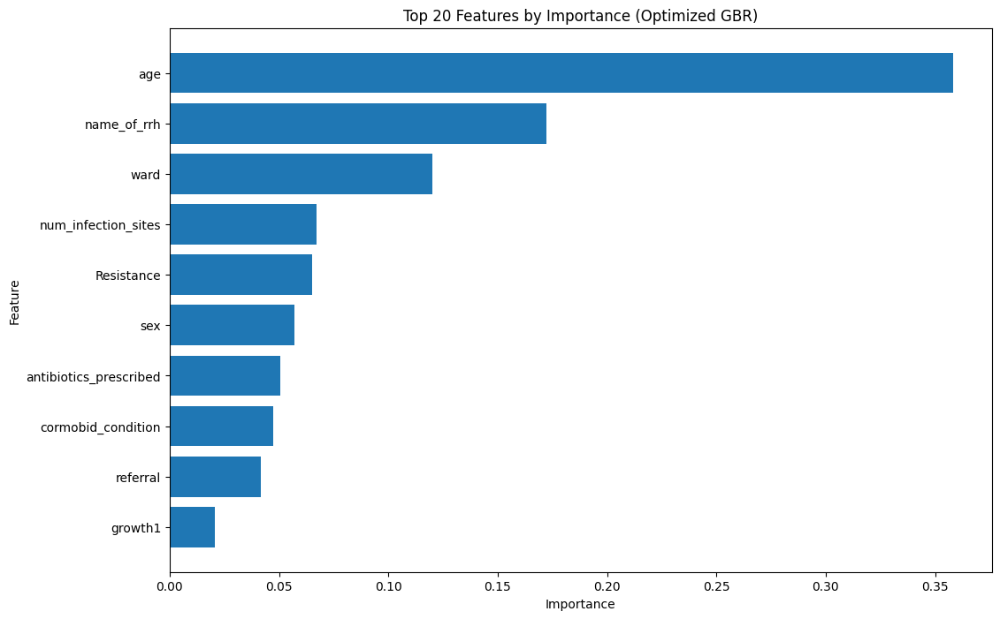

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Log-transform the target variable
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Define the hyperparameter grid (smaller range to avoid excessive runtime)
param_grid = {
    'n_estimators': [500, 1500],
    'learning_rate': [0.001, 0.05, 0.01],
    'max_depth': [3, 5, 10],
    'min_samples_split': [5, 12],
    'min_samples_leaf': [2, 5],
    'subsample': [0.6, 0.8, 1.0],
    'random_state': [42]
}

# Initialize model
gbr = GradientBoostingRegressor(random_state=42)

# Perform Grid Search
grid_search = GridSearchCV(
    gbr, param_grid, 
    cv=3, scoring='neg_mean_absolute_error', 
    n_jobs=-1, verbose=2
)
print("\nOptimizing hyperparameters using Grid Search...")
grid_search.fit(X_train, y_train_log)

# Retrieve best model
best_gbr = grid_search.best_estimator_
print("\nBest Parameters:", grid_search.best_params_)

# Cross-validation on training set
cv_scores = cross_val_score(best_gbr, X_train, y_train_log, cv=5, scoring='r2')
print(f"Cross-validation R2 Score: {np.mean(cv_scores):.4f}")

# Evaluate model on validation and test sets
for X_set, y_set_log, y_set, label in [(X_val, y_val_log, y_val, 'Validation'), (X_test, y_test_log, y_test, 'Test')]:
    y_pred_log = best_gbr.predict(X_set)
    y_pred = np.expm1(y_pred_log)  # Convert back from log scale
    y_actual = np.expm1(y_set_log)  # Convert back for comparison

    # Compute metrics
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    print(f"\n{label} Metrics:")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}")
    print(f"R-squared Score: {r2:.4f}")

    # Scatter plot for actual vs. predicted values
    plt.figure(figsize=(6, 6))
    plt.scatter(y_actual, y_pred, alpha=0.5)
    plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
    plt.xlabel('Actual Length of Stay')
    plt.ylabel('Predicted Length of Stay')
    plt.title(f'{label} Set: Actual vs Predicted Length of Stay')
    plt.show()

# Feature importance
feature_importance = pd.DataFrame({'Feature': X_train.columns, 'Importance': best_gbr.feature_importances_}).sort_values('Importance', ascending=False)

# Plot top 20 features
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'][:20], feature_importance['Importance'][:20])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 20 Features by Importance (Optimized GBR)')
plt.gca().invert_yaxis()  # Highest importance at top
plt.show()


# Light gbm regressor

Training set: 3772 samples
Validation set: 944 samples
Test set: 1179 samples

Training LightGBM model...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000410 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 132
[LightGBM] [Info] Number of data points in the train set: 3772, number of used features: 10
[LightGBM] [Info] Start training from score 2.822924
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits w

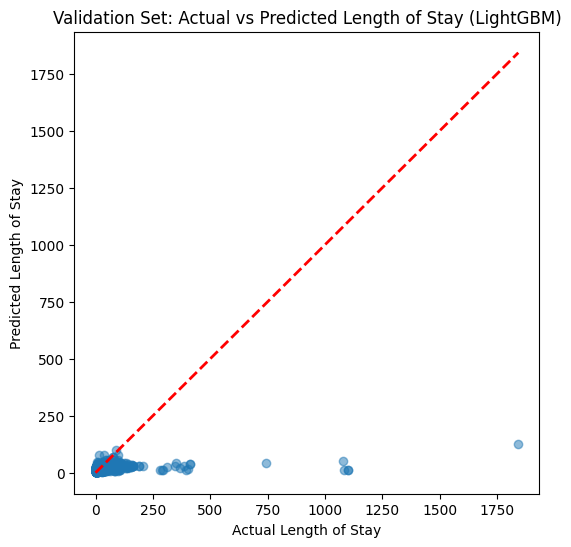


Test Metrics:
Mean Absolute Error: 22.90
Root Mean Squared Error: 90.64
R-squared Score: 0.0484


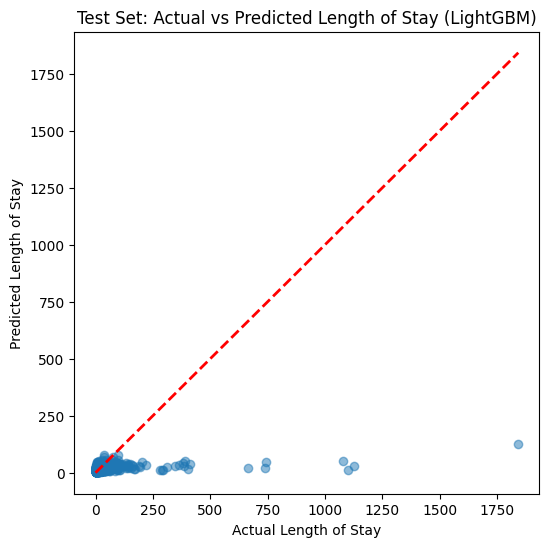

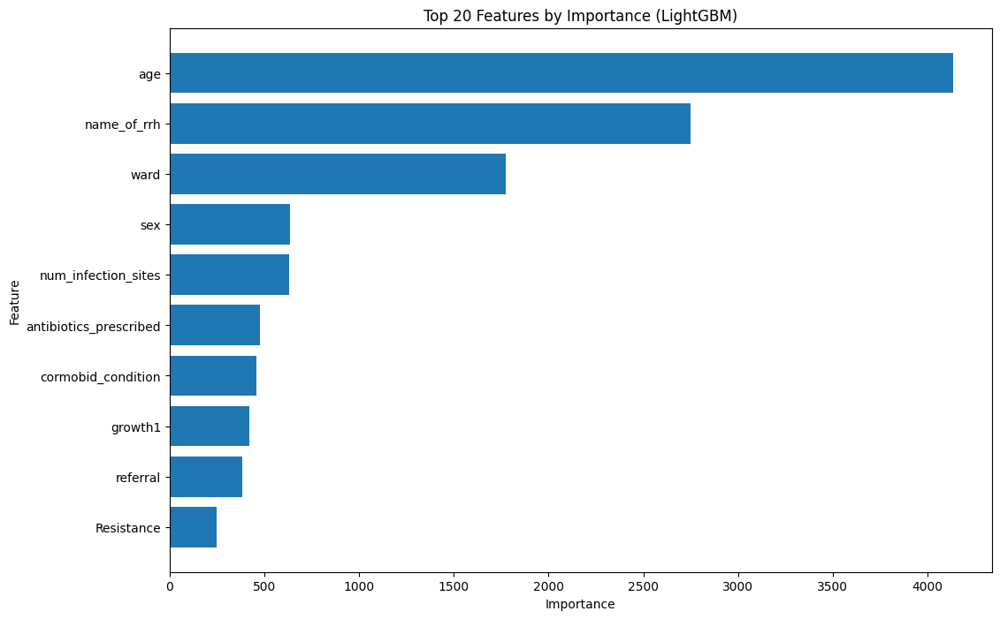

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from lightgbm import LGBMRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Log-transform the target variable
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Define LightGBM model (default settings)
lgbm = lgb.LGBMRegressor(random_state=42)

params = {
    'objective' : 'regression',
    'random_state': 42,
    'n_estimators': 1000,         # Significantly increased for better fit
    'learning_rate': 0.01,       # Further reduced for more precise corrections
    'max_depth': 4,               # Increased to capture more complex patterns
    'num_leaves': 85, 
    'boosting_type' : 'gbdt',
    'subsample_for_bin'  : 25000               
}

# Train the model
print("\nTraining LightGBM model...")
lgbm = lgb.LGBMRegressor(**params)
lgbm.fit(X_train, y_train_log)

# Cross-validation on training set
cv_scores = cross_val_score(lgbm, X_train, y_train_log, cv=5, scoring='r2')
print(f"Cross-validation R2 Score: {np.mean(cv_scores):.4f}")

# Evaluate model on validation and test sets
for X_set, y_set_log, y_set, label in [(X_val, y_val_log, y_val, 'Validation'), (X_test, y_test_log, y_test, 'Test')]:
    y_pred_log = lgbm.predict(X_set)
    y_pred = np.expm1(y_pred_log)  # Convert back from log scale
    y_actual = np.expm1(y_set_log)  # Convert back for comparison

    # Compute metrics
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    print(f"\n{label} Metrics:")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}")
    print(f"R-squared Score: {r2:.4f}")

    # Scatter plot for actual vs. predicted values
    plt.figure(figsize=(6, 6))
    plt.scatter(y_actual, y_pred, alpha=0.5)
    plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
    plt.xlabel('Actual Length of Stay')
    plt.ylabel('Predicted Length of Stay')
    plt.title(f'{label} Set: Actual vs Predicted Length of Stay (LightGBM)')
    plt.show()

# Feature importance
feature_importance = pd.DataFrame({'Feature': X_train.columns, 'Importance': lgbm.feature_importances_}).sort_values('Importance', ascending=False)

# Plot top 20 features
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'][:20], feature_importance['Importance'][:20])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 20 Features by Importance (LightGBM)')
plt.gca().invert_yaxis()  # Highest importance at top
plt.show()


Training set: 3772 samples
Validation set: 944 samples
Test set: 1179 samples

Performing Random Search Optimization...


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001108 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 129
[LightGBM] [Info] Number of data points in the train set: 2515, number of used features: 10
[LightGBM] [Info] Start training from score 2.817393
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004008 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 129
[LightGBM] [Info] Number of data points in the train set: 2515, number of used features: 10
[LightGBM] [Info] Start training from score 2.838741
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003017 seconds.
You can set `

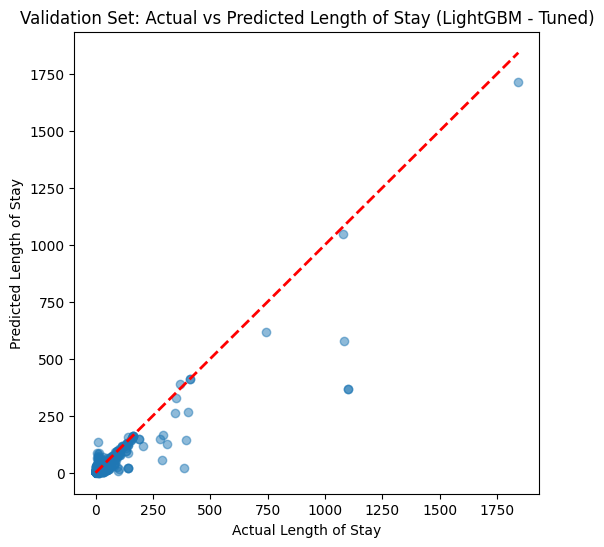


Test Metrics:
Mean Absolute Error: 9.47
Root Mean Squared Error: 38.00
R-squared Score: 0.8328


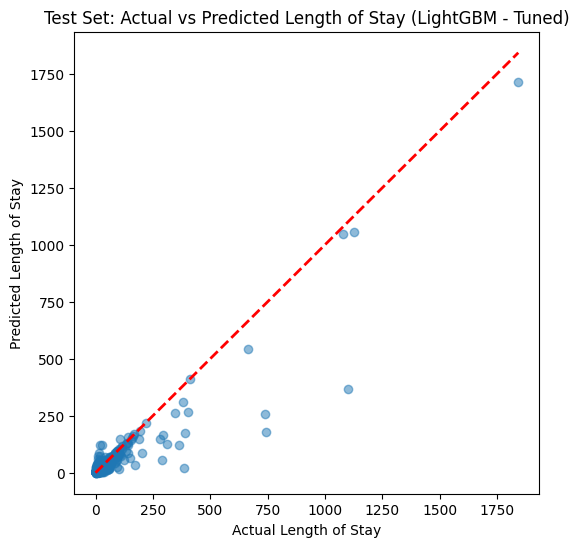

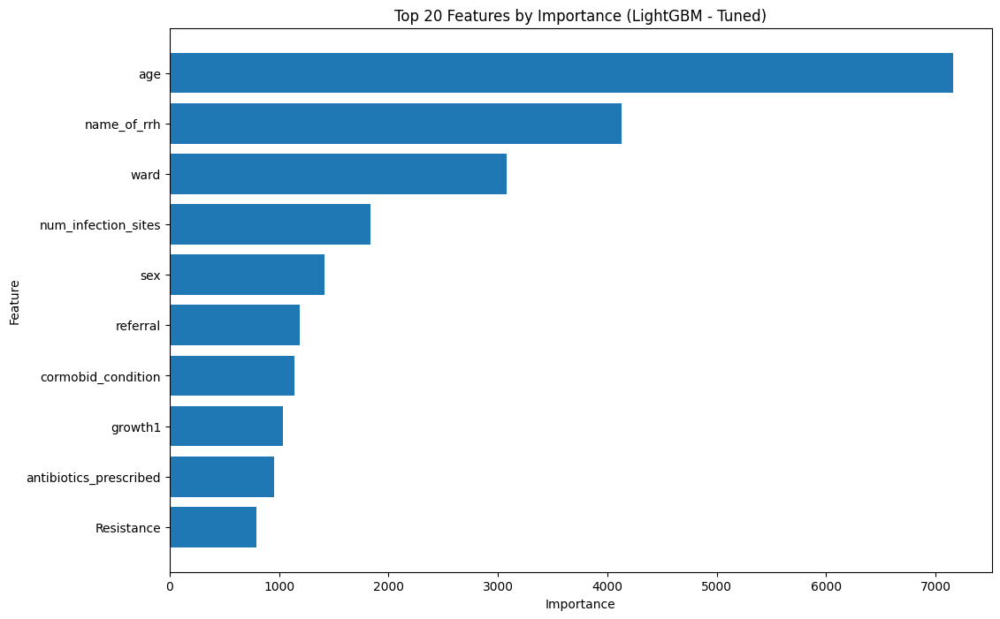

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import randint, uniform

# Log-transform the target variable
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Define hyperparameter grid
param_dist = {
    'num_leaves': randint(20, 150),
    'max_depth': randint(3, 12),
    'learning_rate': uniform(0.01, 0.2),
    'n_estimators': randint(100, 2000),
    'min_child_samples': randint(5, 50),
    'subsample': uniform(0.5, 0.5),
    'colsample_bytree': uniform(0.5, 0.5),
    'reg_alpha': uniform(0, 1),
    'reg_lambda': uniform(0, 1)
}

# Define LightGBM model
lgbm = lgb.LGBMRegressor(random_state=42)

# Randomized search
random_search = RandomizedSearchCV(
    lgbm, param_distributions=param_dist, 
    n_iter=30, scoring='neg_mean_absolute_error', cv=3, random_state=42, n_jobs=-1
)

print("\nPerforming Random Search Optimization...")
random_search.fit(X_train, y_train_log)

# Best parameters
print("\nBest Hyperparameters Found:")
print(random_search.best_params_)

# Train best model on full training set
best_lgbm = random_search.best_estimator_
cv_scores = cross_val_score(best_lgbm, X_train, y_train_log, cv=5, scoring='r2')
print(f"Cross-validation R2 Score: {np.mean(cv_scores):.4f}")

# Evaluate on validation and test sets
for X_set, y_set_log, y_set, label in [(X_val, y_val_log, y_val, 'Validation'), (X_test, y_test_log, y_test, 'Test')]:
    y_pred_log = best_lgbm.predict(X_set)
    y_pred = np.expm1(y_pred_log)  # Convert back from log scale
    y_actual = np.expm1(y_set_log)  # Convert back for comparison

    # Compute metrics
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    print(f"\n{label} Metrics:")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}")
    print(f"R-squared Score: {r2:.4f}")

    # Scatter plot for actual vs. predicted values
    plt.figure(figsize=(6, 6))
    plt.scatter(y_actual, y_pred, alpha=0.5)
    plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
    plt.xlabel('Actual Length of Stay')
    plt.ylabel('Predicted Length of Stay')
    plt.title(f'{label} Set: Actual vs Predicted Length of Stay (LightGBM - Tuned)')
    plt.show()

# Feature importance
feature_importance = pd.DataFrame({'Feature': X_train.columns, 'Importance': best_lgbm.feature_importances_}).sort_values('Importance', ascending=False)

# Plot top 20 features
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'][:20], feature_importance['Importance'][:20])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 20 Features by Importance (LightGBM - Tuned)')
plt.gca().invert_yaxis()  # Highest importance at top
plt.show()


Training set: 3772 samples
Validation set: 944 samples
Test set: 1179 samples

Performing Random Search Optimization...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003063 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 128
[LightGBM] [Info] Number of data points in the train set: 2514, number of used features: 10
[LightGBM] [Info] Start training from score 2.812634
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003125 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 129
[LightGBM] [Info] Number of data points in the train set: 2515, number of used features: 10
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002108 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough

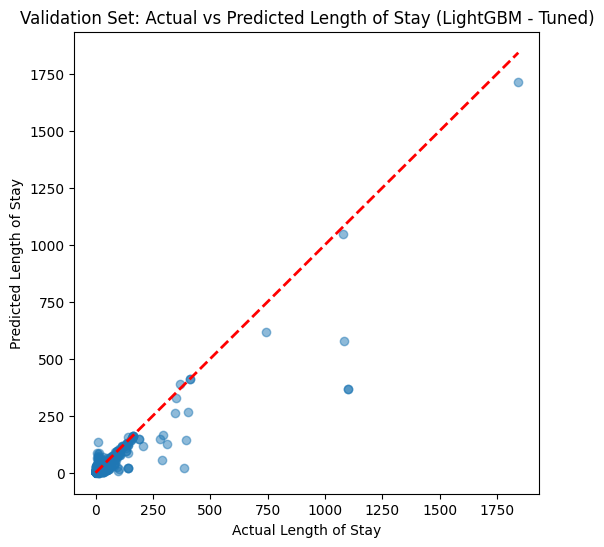


Test Metrics:
Mean Absolute Error: 9.47
Root Mean Squared Error: 38.00
R-squared Score: 0.8328


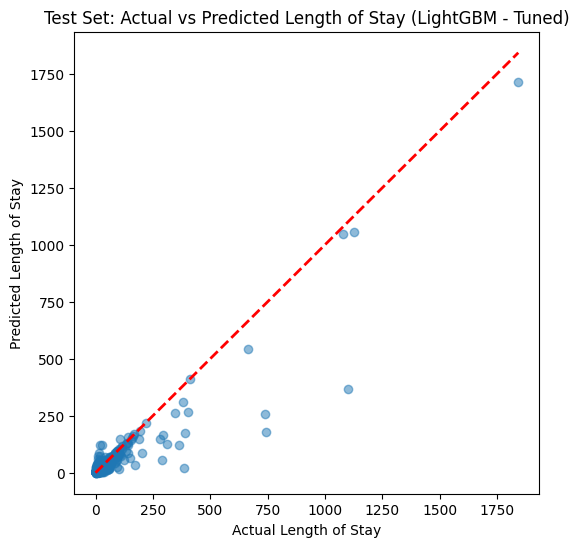

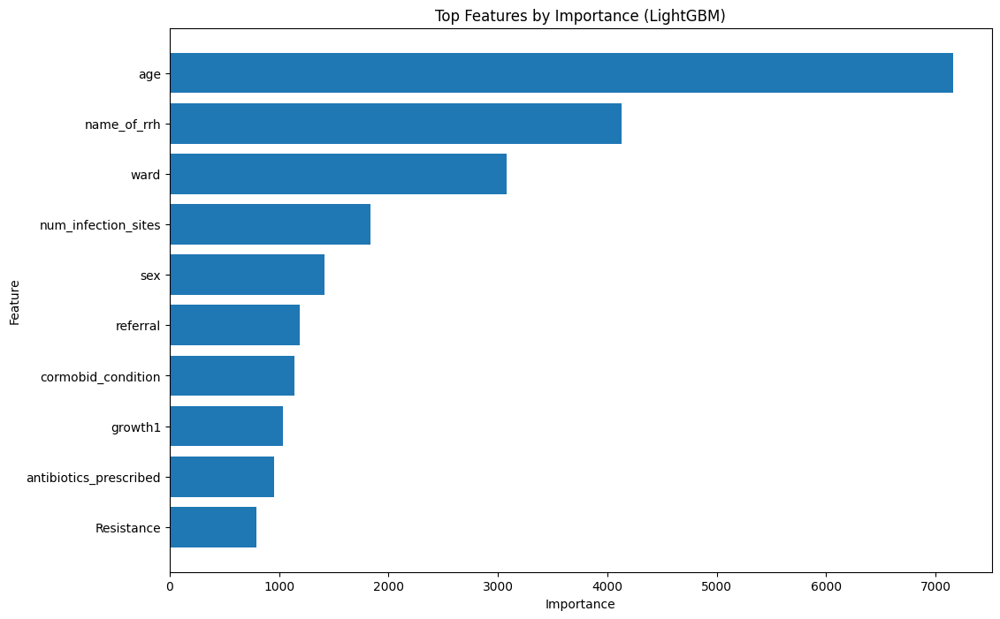

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import randint, uniform

# Log-transform the target variable
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Define hyperparameter grid
param_dist = {
    'num_leaves': randint(20, 150),
    'max_depth': randint(3, 12),
    'learning_rate': uniform(0.01, 0.2),
    'n_estimators': randint(100, 2000),
    'min_child_samples': randint(5, 50),
    'subsample': uniform(0.5, 0.5),
    'colsample_bytree': uniform(0.5, 0.5),
    'reg_alpha': uniform(0, 1),
    'reg_lambda': uniform(0, 1)
}

# Define LightGBM model
lgbm = lgb.LGBMRegressor(random_state=42)

# Randomized search
random_search = RandomizedSearchCV(
    lgbm, param_distributions=param_dist, 
    n_iter=30, scoring='neg_mean_absolute_error', cv=3, random_state=42, n_jobs=-1
)

print("\nPerforming Random Search Optimization...")
random_search.fit(X_train, y_train_log)

# Best parameters
print("\nBest Hyperparameters Found:")
print(random_search.best_params_)

# Train best model on full training set
best_lgbm = random_search.best_estimator_
cv_scores = cross_val_score(best_lgbm, X_train, y_train_log, cv=5, scoring='r2')
print(f"Cross-validation R2 Score: {np.mean(cv_scores):.4f}")

# Evaluate on validation and test sets
for X_set, y_set_log, y_set, label in [(X_val, y_val_log, y_val, 'Validation'), (X_test, y_test_log, y_test, 'Test')]:
    y_pred_log = best_lgbm.predict(X_set)
    y_pred = np.expm1(y_pred_log)  # Convert back from log scale
    y_actual = np.expm1(y_set_log)  # Convert back for comparison

    # Compute metrics
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    print(f"\n{label} Metrics:")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}")
    print(f"R-squared Score: {r2:.4f}")

    # Scatter plot for actual vs. predicted values
    plt.figure(figsize=(6, 6))
    plt.scatter(y_actual, y_pred, alpha=0.5)
    plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
    plt.xlabel('Actual Length of Stay')
    plt.ylabel('Predicted Length of Stay')
    plt.title(f'{label} Set: Actual vs Predicted Length of Stay (LightGBM - Tuned)')
    plt.show()

# Feature importance
feature_importance = pd.DataFrame({'Feature': X_train.columns, 'Importance': best_lgbm.feature_importances_}).sort_values('Importance', ascending=False)

# Plot top 20 features
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'][:20], feature_importance['Importance'][:20])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top Features by Importance (LightGBM)')
plt.gca().invert_yaxis()  # Highest importance at top
plt.show()


# Extreme gradient boost

Training set: 3772 samples
Validation set: 944 samples
Test set: 1179 samples

Training XGBoost model...
Cross-validation R2 Score: 0.2126

Validation Metrics:
Mean Absolute Error: 29.78
Root Mean Squared Error: 105.71
R-squared Score: -0.0043


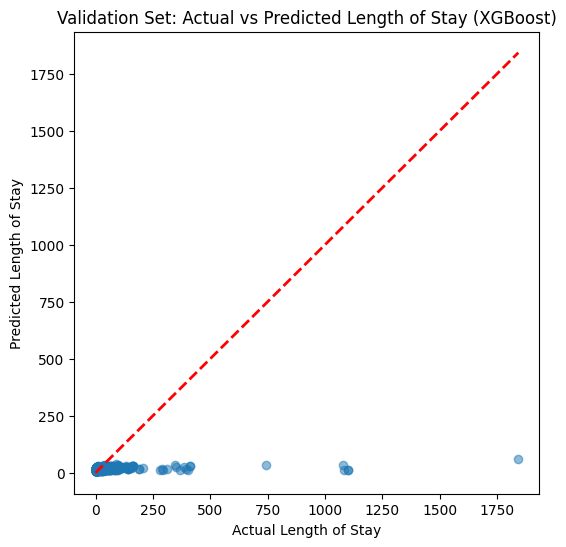


Test Metrics:
Mean Absolute Error: 23.05
Root Mean Squared Error: 92.51
R-squared Score: 0.0089


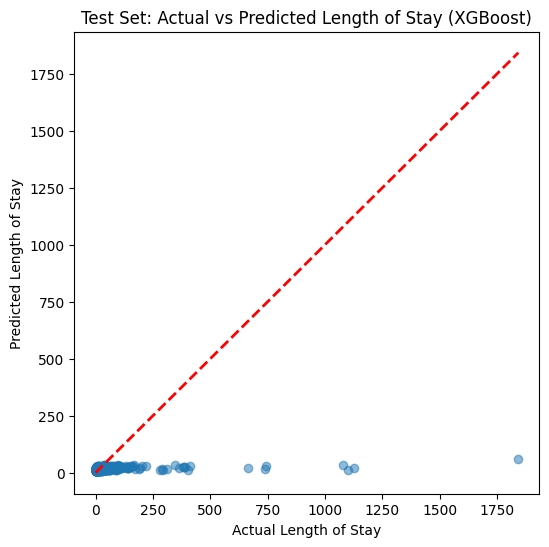

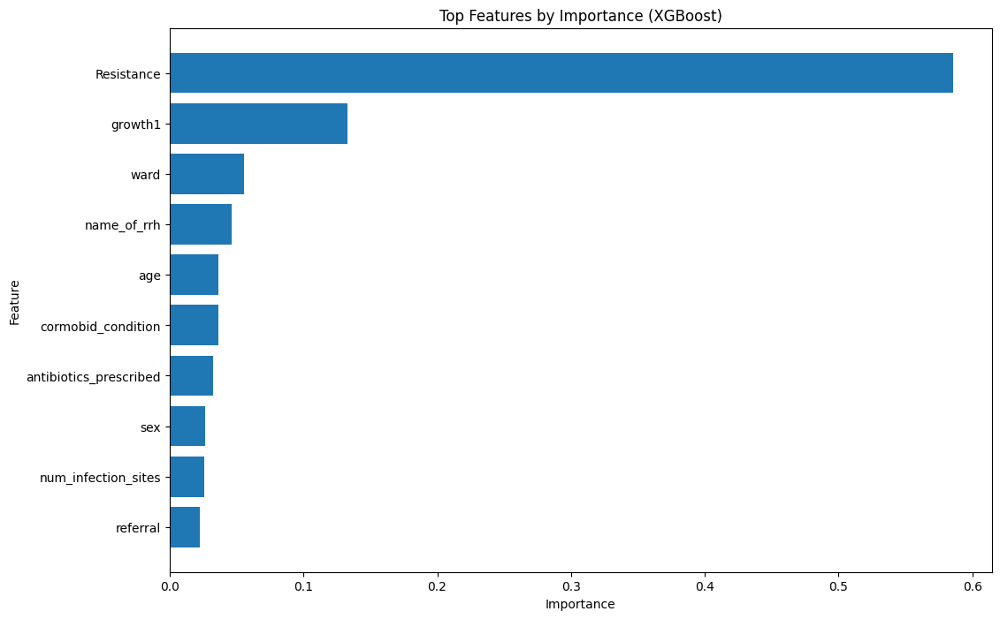

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Log-transform the target variable
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Define initial XGBoost model (without optimization)
xgb_params = {
    'objective': 'reg:squarederror',  # Regression task
    'n_estimators': 1000,
    'learning_rate': 0.001,
    'max_depth': 6,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'random_state': 42
}

# Train the model
print("\nTraining XGBoost model...")
xgb_reg = xgb.XGBRegressor(**xgb_params)
xgb_reg.fit(X_train, y_train_log)

# Cross-validation on training set
cv_scores = cross_val_score(xgb_reg, X_train, y_train_log, cv=3, scoring='r2')
print(f"Cross-validation R2 Score: {np.mean(cv_scores):.4f}")

# Evaluate model on validation and test sets
for X_set, y_set_log, y_set, label in [(X_val, y_val_log, y_val, 'Validation'), (X_test, y_test_log, y_test, 'Test')]:
    y_pred_log = xgb_reg.predict(X_set)
    y_pred = np.expm1(y_pred_log)  # Convert back from log scale
    y_actual = np.expm1(y_set_log)  # Convert back for comparison

    # Compute metrics
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    print(f"\n{label} Metrics:")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}")
    print(f"R-squared Score: {r2:.4f}")

    # Scatter plot for actual vs. predicted values
    plt.figure(figsize=(6, 6))
    plt.scatter(y_actual, y_pred, alpha=0.5)
    plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
    plt.xlabel('Actual Length of Stay')
    plt.ylabel('Predicted Length of Stay')
    plt.title(f'{label} Set: Actual vs Predicted Length of Stay (XGBoost)')
    plt.show()

# Feature importance
feature_importance = pd.DataFrame({'Feature': X_train.columns, 'Importance': xgb_reg.feature_importances_}).sort_values('Importance', ascending=False)

# Plot top 20 features
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'][:20], feature_importance['Importance'][:20])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top Features by Importance (XGBoost)')
plt.gca().invert_yaxis()  # Highest importance at top
plt.show()


Training set: 3772 samples
Validation set: 944 samples
Test set: 1179 samples

Performing Grid Search Optimization...
Fitting 3 folds for each of 2187 candidates, totalling 6561 fits

Best Hyperparameters Found:
{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 1000, 'reg_alpha': 0, 'reg_lambda': 0.1, 'subsample': 1.0}
Cross-validation R2 Score: 0.6609

Validation Metrics:
Mean Absolute Error: 6.75
Root Mean Squared Error: 21.15
R-squared Score: 0.9598


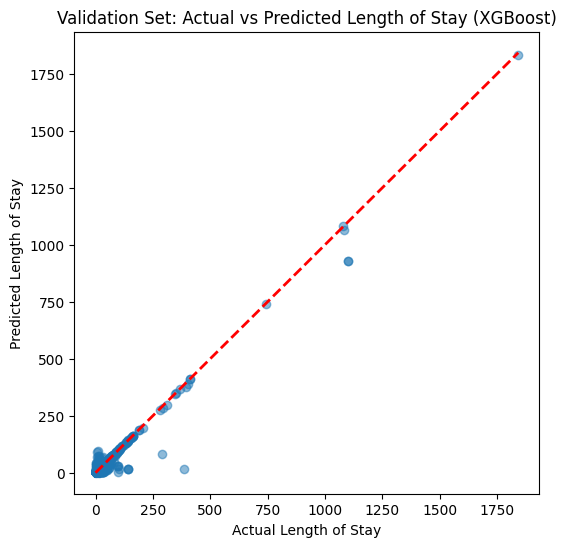


Test Metrics:
Mean Absolute Error: 4.56
Root Mean Squared Error: 18.51
R-squared Score: 0.9603


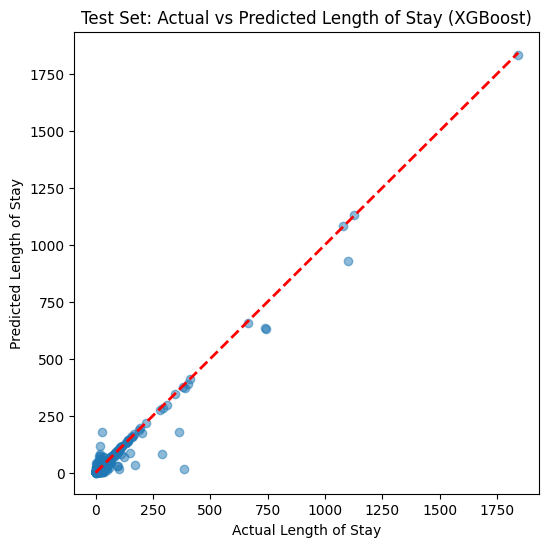

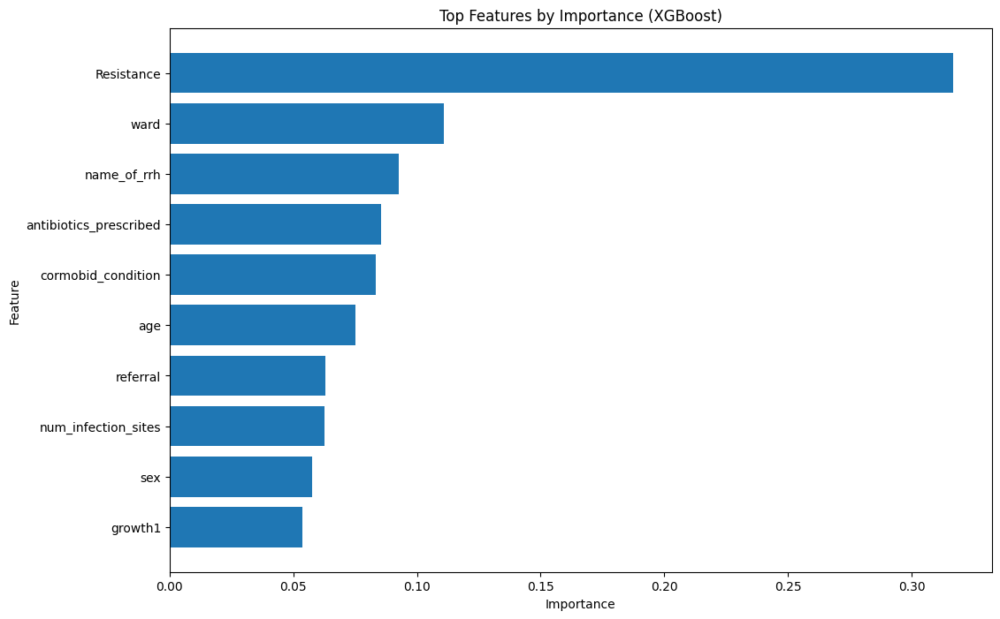

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Example: Assume X_train, X_val, X_test and y_train, y_val, y_test are already defined.
# Log-transform the target variable for training, validation, and testing
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Define a smaller hyperparameter grid for Grid Search
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 500, 1000],
    'subsample': [0.5, 0.75, 1.0],
    'colsample_bytree': [0.5, 0.75, 1.0],
    'reg_alpha': [0, 0.1, 0.5],
    'reg_lambda': [0, 0.1, 0.5]
}

# Initialize the XGBoost regressor
xgb_model = xgb.XGBRegressor(random_state=42, objective='reg:squarederror')

# Set up GridSearchCV
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=3,
    n_jobs=-1,
    verbose=1
)

print("\nPerforming Grid Search Optimization...")
grid_search.fit(X_train, y_train_log)

# Output best hyperparameters
print("\nBest Hyperparameters Found:")
print(grid_search.best_params_)

# Retrieve the best model
best_xgb = grid_search.best_estimator_

# Evaluate performance using 5-fold cross-validation (R2 score)
cv_scores = cross_val_score(best_xgb, X_train, y_train_log, cv=5, scoring='r2')
print(f"Cross-validation R2 Score: {np.mean(cv_scores):.4f}")

# Evaluate on validation and test sets
for X_set, y_set_log, y_set, label in [
    (X_val, y_val_log, y_val, 'Validation'),
    (X_test, y_test_log, y_test, 'Test')
]:
    # Predict in log-space and then convert back
    y_pred_log = best_xgb.predict(X_set)
    y_pred = np.expm1(y_pred_log)         # Convert predictions back to original scale
    y_actual = np.expm1(y_set_log)         # Convert actual values back for comparison

    # Calculate metrics
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    print(f"\n{label} Metrics:")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}")
    print(f"R-squared Score: {r2:.4f}")

    # Scatter plot: Actual vs. Predicted values
    plt.figure(figsize=(6, 6))
    plt.scatter(y_actual, y_pred, alpha=0.5)
    plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
    plt.xlabel('Actual Length of Stay')
    plt.ylabel('Predicted Length of Stay')
    plt.title(f'{label} Set: Actual vs Predicted Length of Stay (XGBoost)')
    plt.show()

# Plot feature importance from the best model
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_xgb.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'][:20], feature_importance['Importance'][:20])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top Features by Importance (XGBoost)')
plt.gca().invert_yaxis()  # Highest importance at the top
plt.show()


In [46]:
import pickle

In [47]:
with open('xgb_model1.pkl', 'wb') as file:
    pickle.dump(best_xgb, file)

In [48]:
# loading the model.

# with open('xgb_model.pkl', 'rb') as file:
#     loaded_model = pickle.load(file)

# Lasso Elastic Regressor

Training set: 3772 samples
Validation set: 944 samples
Test set: 1179 samples

Validation Metrics:
Mean Absolute Error: 565339748306202230935653818826752.00
Root Mean Squared Error: 7781884986464121918523182950645760.00
R-squared Score: -5442770952800639171615148181576645329024190907957395430054035456.0000


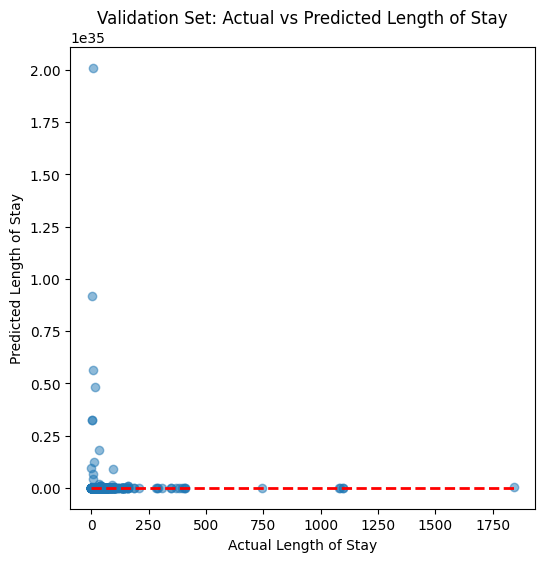


Test Metrics:
Mean Absolute Error: 501411635724427019703351930519552.00
Root Mean Squared Error: 8613097963787600674572857002426368.00
R-squared Score: -8591622088257245764602982204582966661219722402896395408848715776.0000


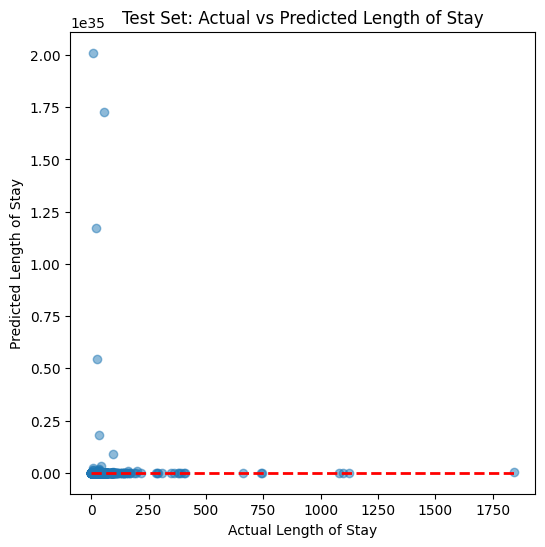

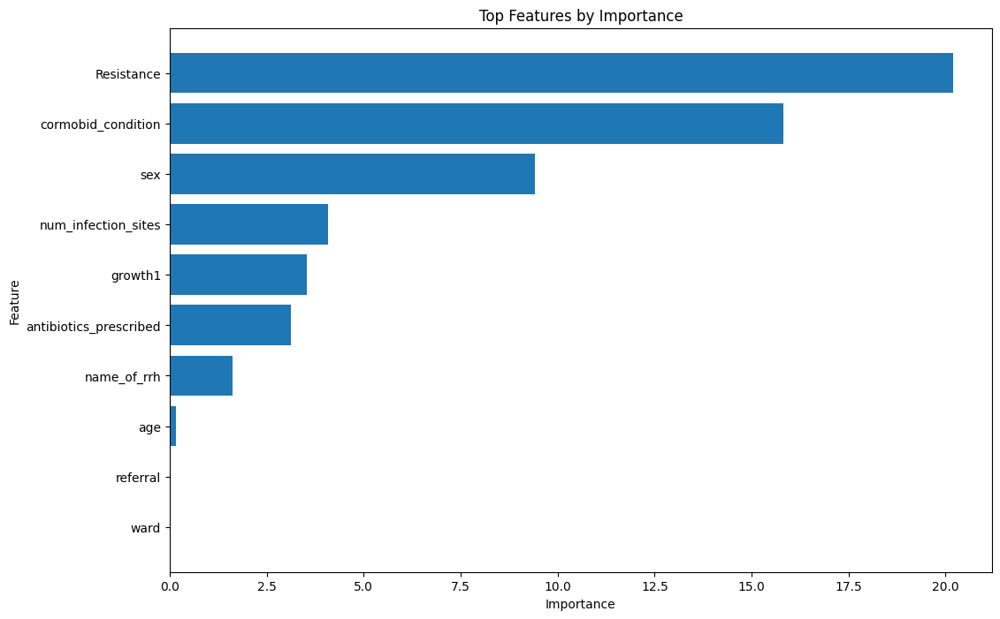

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Log-transform the target variable
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

params = {
    'random_state':10,
    'alpha' : 00.006551,
    'fit_intercept' : True,
    'copy_X' : True,
    'max_iter' : 1500,
    'positive' : True
}


# Initialize and train the Light Gradient Boosting Regressor
lasso = Lasso(**params)
lasso.fit(X_train, y_train)

# Evaluate model on validation and test sets
for X_set, y_set_log, y_set, label in [(X_val, y_val_log, y_val, 'Validation'), (X_test, y_test_log, y_test, 'Test')]:
    y_pred_log = lasso.predict(X_set)
    y_pred = np.expm1(y_pred_log)  # Convert back from log scale
    y_actual = np.expm1(y_set_log)  # Convert back for comparison

    # Compute metrics
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    print(f"\n{label} Metrics:")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}")
    print(f"R-squared Score: {r2:.4f}")

    # Scatter plot for actual vs. predicted values
    plt.figure(figsize=(6, 6))
    plt.scatter(y_actual, y_pred, alpha=0.5)
    plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
    plt.xlabel('Actual Length of Stay')
    plt.ylabel('Predicted Length of Stay')
    plt.title(f'{label} Set: Actual vs Predicted Length of Stay')
    plt.show()

# Feature importance
feature_importance = pd.DataFrame({'Feature': X_train.columns, 'Importance': np.abs(lasso.coef_)}).sort_values('Importance', ascending=False)

# Plot top 20 features
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'][:20], feature_importance['Importance'][:20])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top Features by Importance')
plt.gca().invert_yaxis()  # Highest importance at top
plt.show()


Training set: 3772 samples
Validation set: 944 samples
Test set: 1179 samples
Fitting 3 folds for each of 6 candidates, totalling 18 fits
[CV] END .......................................alpha=0.0001; total time=   0.0s
[CV] END ........................................alpha=0.001; total time=   0.0s
[CV] END .......................................alpha=0.0001; total time=   0.0s
[CV] END .......................................alpha=0.0001; total time=   0.0s
[CV] END ........................................alpha=0.001; total time=   0.0s
[CV] END ........................................alpha=0.001; total time=   0.0s
[CV] END .........................................alpha=0.01; total time=   0.0s
[CV] END .........................................alpha=0.01; total time=   0.0s
[CV] END ..........................................alpha=0.1; total time=   0.0s
[CV] END .........................................alpha=0.01; total time=   0.0s
[CV] END ..........................................a

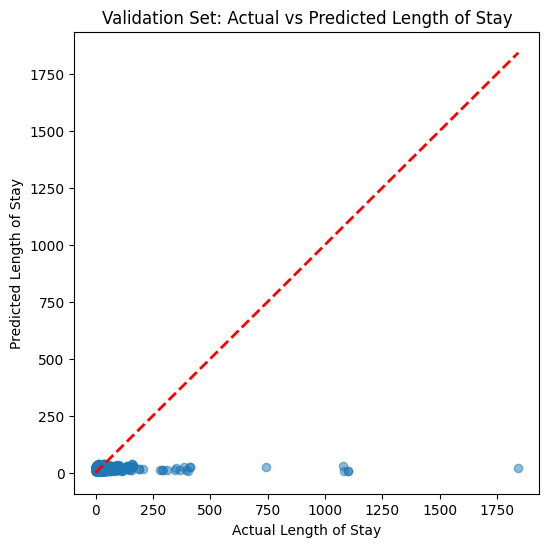


Test Metrics:
Mean Absolute Error: 24.26
Root Mean Squared Error: 93.81
R-squared Score: -0.0192


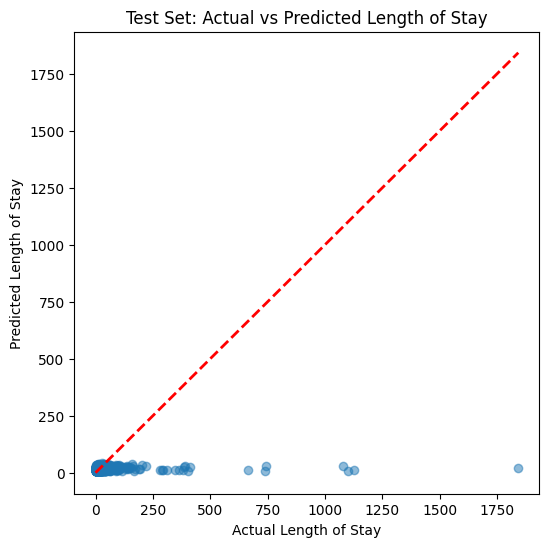

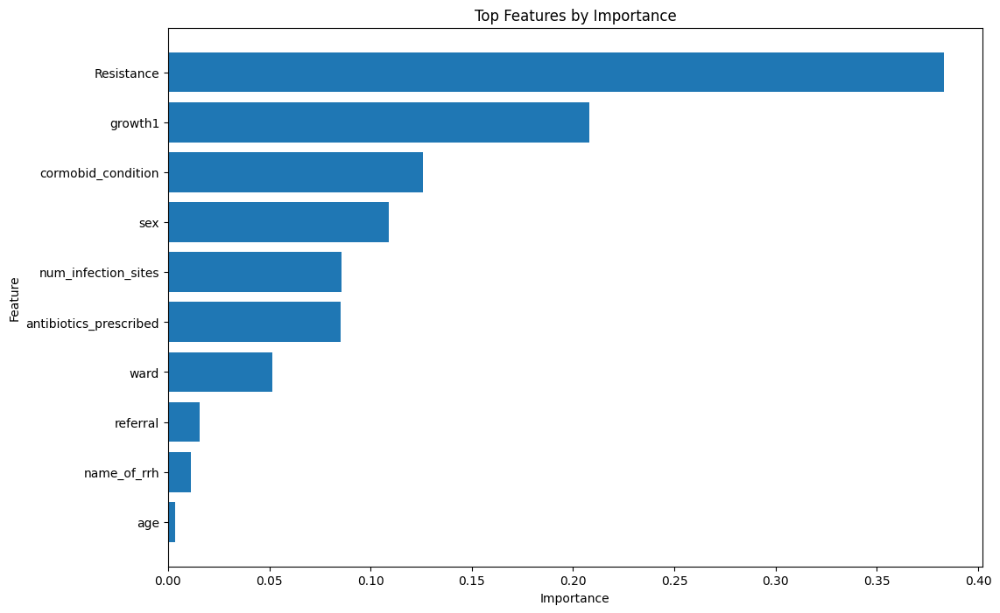

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Log-transform the target variable
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Define parameter grid for optimization
param_grid = {'alpha': [0.0001, 0.001, 0.01, 0.1, 1, 10]}

# Initialize Lasso model
lasso = Lasso(random_state=42, max_iter=10000)

# Perform Grid Search
grid_search = GridSearchCV(lasso, param_grid, cv=3, scoring='r2', n_jobs=-1, verbose=2)
grid_search.fit(X_train, y_train_log)

# Best parameters and model
best_params = grid_search.best_params_
print("Best parameters found: ", best_params)
best_lasso = grid_search.best_estimator_

# Evaluate model on validation and test sets
for X_set, y_set_log, y_set, label in [(X_val, y_val_log, y_val, 'Validation'), (X_test, y_test_log, y_test, 'Test')]:
    y_pred_log = best_lasso.predict(X_set)
    y_pred = np.expm1(y_pred_log)  # Convert back from log scale
    y_actual = np.expm1(y_set_log)  # Convert back for comparison

    # Compute metrics
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    print(f"\n{label} Metrics:")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}")
    print(f"R-squared Score: {r2:.4f}")

    # Scatter plot for actual vs. predicted values
    plt.figure(figsize=(6, 6))
    plt.scatter(y_actual, y_pred, alpha=0.5)
    plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
    plt.xlabel('Actual Length of Stay')
    plt.ylabel('Predicted Length of Stay')
    plt.title(f'{label} Set: Actual vs Predicted Length of Stay')
    plt.show()

# Feature importance
feature_importance = pd.DataFrame({'Feature': X_train.columns, 'Importance': np.abs(best_lasso.coef_)}).sort_values('Importance', ascending=False)

# Plot top 20 features
plt.figure(figsize=(12, 8))
plt.barh(feature_importance['Feature'][:20], feature_importance['Importance'][:20])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top Features by Importance')
plt.gca().invert_yaxis()  # Highest importance at top
plt.show()


# KNN Regressor

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Log-transform the target variable
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Define the model hyperparameters for Light Gradient Boosting
params = {
    'n_neighbors': 5,
    'weights': 'distance',
    'algorithm': 'auto',
    'leaf_size': 45,
    'p': 1,
    'metric': 'minkowski'
}


# Initialize and train the Light Gradient Boosting Regressor
knn = KNeighborsRegressor(**params)
knn.fit(X_train, y_train)

# Evaluate model on validation and test sets
for X_set, y_set_log, y_set, label in [(X_val, y_val_log, y_val, 'Validation'), (X_test, y_test_log, y_test, 'Test')]:
    y_pred_log = knn.predict(X_set)
    y_pred = np.expm1(y_pred_log)  # Convert back from log scale
    y_actual = np.expm1(y_set_log)  # Convert back for comparison

    # Compute metrics
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    print(f"\n{label} Metrics:")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}")
    print(f"R-squared Score: {r2:.4f}")

    # Scatter plot for actual vs. predicted values
    plt.figure(figsize=(6, 6))
    plt.scatter(y_actual, y_pred, alpha=0.5)
    plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
    plt.xlabel('Actual Length of Stay')
    plt.ylabel('Predicted Length of Stay')
    plt.title(f'{label} Set: Actual vs Predicted Length of Stay')
    plt.show()


Training set: 3772 samples
Validation set: 944 samples
Test set: 1179 samples


/tmp/ipykernel_84010/428890932.py:35: RuntimeWarning: overflow encountered in expm1
  y_pred = np.expm1(y_pred_log)  # Convert back from log scale


ValueError: Input contains infinity or a value too large for dtype('float64').

Training set: 953 samples
Validation set: 239 samples
Test set: 298 samples
Best parameters: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}

Validation Metrics:
Mean Absolute Error: 4.67
Root Mean Squared Error: 14.30
R-squared Score: 0.8450


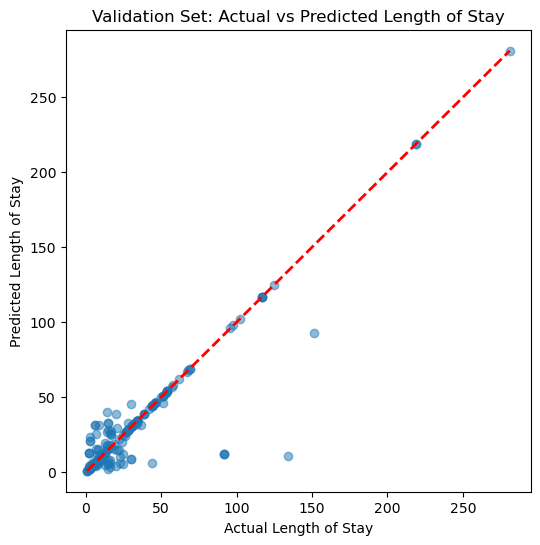


Test Metrics:
Mean Absolute Error: 1.62
Root Mean Squared Error: 5.79
R-squared Score: 0.9439


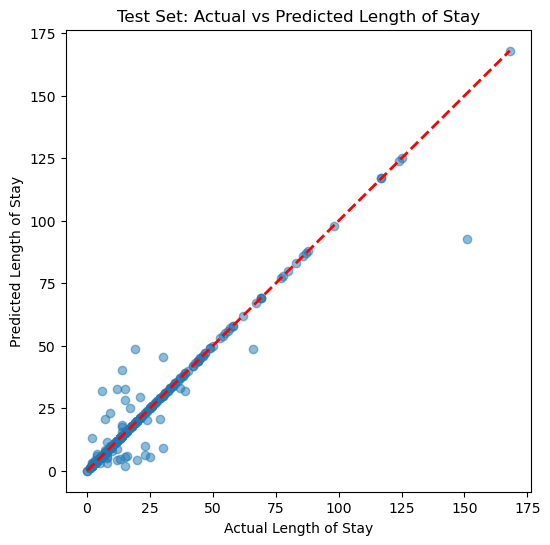

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Log-transform the target variable
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Define hyperparameter grid
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

# Initialize KNN model
knn = KNeighborsRegressor()

# Perform Grid Search
grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='r2', n_jobs=-1)
grid_search.fit(X_train, y_train_log)

# Best model from Grid Search
best_knn = grid_search.best_estimator_
print(f"Best parameters: {grid_search.best_params_}")

# Evaluate best model on validation and test sets
for X_set, y_set_log, y_set, label in [(X_val, y_val_log, y_val, 'Validation'), (X_test, y_test_log, y_test, 'Test')]:
    y_pred_log = best_knn.predict(X_set)
    y_pred = np.expm1(y_pred_log)  # Convert back from log scale
    y_actual = np.expm1(y_set_log)  # Convert back for comparison

    # Compute metrics
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    print(f"\n{label} Metrics:")
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}")
    print(f"R-squared Score: {r2:.4f}")

    # Scatter plot for actual vs. predicted values
    plt.figure(figsize=(6, 6))
    plt.scatter(y_actual, y_pred, alpha=0.5)
    plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 'r--', lw=2)
    plt.xlabel('Actual Length of Stay')
    plt.ylabel('Predicted Length of Stay')
    plt.title(f'{label} Set: Actual vs Predicted Length of Stay')
    plt.show()
